# Đồ án Advanced Machine Learning — Dự báo giao thông bền vững khi cảm biến hỏng / dữ liệu lệch phân phối

**Bài toán.** Dự báo **lưu lượng xe (flow)** của 307 cảm biến PeMS04 sau **15 / 30 / 60 phút** từ 12 bước lịch sử (5 phút/bước), trong điều kiện một phần cảm biến **mất dữ liệu** lúc suy luận (test) mà lúc huấn luyện không thấy.

1. Đưa **mặt nạ trạng thái cảm biến** vào input (kênh thứ 2) để mô hình biết giá trị nào là thật, giá trị nào là bù (imputed). Thêm **đặc trưng giờ trong ngày / cuối tuần** (3 kênh).
2. **Masking augmentation**: giả lập cảm biến hỏng ngay trong lúc huấn luyện.
3. Đánh giá theo **kịch bản hỏng có kiểm soát**: 0/10/20/30% cảm biến, mất 15/30 phút, **hỏng cả một khu vực** (cảm biến gần nhau), và **bỏ thông tin không gian** (ma trận kề).

**Dữ liệu.** PeMS04 (Caltrans District 4, 01/01/2018 – 28/02/2018, 16 992 bước × 307 cảm biến × 3 đặc trưng: `flow`, `occupancy`, `speed`). Notebook chỉ lấy **kênh 0 = flow (số xe / 5 phút)** để huấn luyện và dự báo. Có thể quay lại PeMS-Bay (tốc độ, mph) bằng cách đặt `DATASET = "PEMS_BAY"` trong cell cấu hình.

**Quy trình:** load → kiểm tra → mô tả → chia 70/10/20 → hàm `train_model` → so sánh GRU / GNN / STGCN × 3 scaler → chọn model tốt nhất (theo **validation**, không dùng test) → hàm `test_model` với các kịch bản mất dữ liệu → bảng kết quả + biểu đồ.

**Chạy local (RTX 3060 / dGPU):** chọn kernel **Python (aml-traffic)** (venv `/run/media/hoang/HDD-512GB/.venv`). Notebook tự dùng `cuda:0`, dữ liệu local trong `data/pems04`, bật AMP FP16 và chỉ tải `traffic/pems04.zip` từ Hugging Face nếu chưa có file local.

In [1]:
# # install libraries
# # numpy / pandas / matplotlib / IPython đã có sẵn trong Databricks Runtime -> không cài lại.
# # Cluster hiện tại là CPU (Standard_D8ds_v5) -> cài bản PyTorch CPU (bản CUDA không dùng được, chỉ làm nặng môi trường).
# # huggingface_hub: tải traffic/pems04.zip nếu chưa có dữ liệu local.
# # tables: cần cho pd.read_hdf khi chuyển DATASET = "PEMS_BAY".
# # %pip install torch==2.5.1 --index-url https://download.pytorch.org/whl/cpu --extra-index-url https://pypi.org/simple
# %pip install huggingface_hub tables

In [2]:
# # python -m pip install --upgrade pip
# %pip install torch --index-url https://download.pytorch.org/whl/xpu

In [1]:
# ===== 0. Môi trường & cấu hình chạy LOCAL trên dGPU =====
# Kernel khuyến nghị: "Python (aml-traffic)" (= /run/media/hoang/HDD-512GB/.venv).
# Nếu chưa có môi trường: chạy `bash setup_env.sh` một lần trong /run/media/hoang/HDD-512GB.

# --- Thư viện chuẩn và thư viện tính toán ---
import os, sys, time, math, zipfile, random, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from IPython.display import display

# --- Đường dẫn dự án local ---
PROJECT_DIR = Path("/run/media/hoang/HDD-512GB")
if not (PROJECT_DIR / "Do_an_Advanced_ML.ipynb").exists():
    PROJECT_DIR = Path.cwd()
# --- Chọn bộ dữ liệu ---
# PEMS04: 307 cảm biến, npz (T, N, 3) = [flow, occupancy, speed] -> lấy kênh 0 = flow.
# PEMS_BAY: 325 cảm biến, h5 (T, N) = speed (mph). Giữ lại để so sánh nếu cần.
DATASET = "PEMS04"
DATASETS = {
    "PEMS04": dict(dir="pems04", hf_file="traffic/pems04.zip", main_file="pems04.npz",
                   dist_csv="distance.csv", feature_idx=0, feature="flow", unit="xe/5 phút",
                   start="2018-01-01 00:00",
                   # distance.csv chỉ liệt ~340 cạnh nối trực tiếp -> giữ mọi cạnh (không cắt theo ngưỡng).
                   adj_thr=0.0),
    "PEMS_BAY": dict(dir="pems_bay", hf_file="traffic/pems_bay.zip", main_file="pems_bay.h5",
                     dist_csv="distances_bay.csv", feature_idx=None, feature="speed", unit="mph",
                     start=None, adj_thr=0.1),
}
DS = DATASETS[DATASET]
UNIT = DS["unit"]                     # đơn vị hiển thị trên biểu đồ / metric
DATA_DIR = PROJECT_DIR / "data" / DS["dir"]
OUTPUT_DIR = PROJECT_DIR / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)

# --- Cấu hình thí nghiệm ---
# Mọi tham số quan trọng gom một chỗ để dễ tái lập và đổi khi chạy ablation.
CFG = dict(
    # Tái lập
    SEED=42,
    # Dữ liệu
    DATASET=DATASET,
    DATA_DIR=str(DATA_DIR),
    HF_REPO="TorchSpatiotemporal/ProcessedDatasets",
    HF_FILE=DS["hf_file"],            # đường dẫn trên Hugging Face (thư mục traffic/)
    FEATURE_IDX=DS["feature_idx"],    # PEMS04: 0 = flow (1 = occupancy, 2 = speed)
    ADJ_THR=DS["adj_thr"],            # ngưỡng cắt cạnh Gaussian khi dựng ma trận kề
    # Cửa sổ thời gian: 12 bước vào (60 phút), 3 mốc ra (15/30/60 phút)
    N_PAST=12,
    HORIZONS=(3, 6, 12),
    STEP_MIN=5,
    # Chia tập theo thời gian, không shuffle để tránh rò rỉ tương lai
    SPLIT=(0.7, 0.1, 0.2),
    ZERO_AS_MISSING=True,       # flow = 0 (~1.6% ô PeMS04) coi là cảm biến không đo được (quy ước masked-MAE phổ biến)
    # Huấn luyện
    EPOCHS=100, PATIENCE=10, BATCH=64, LR=1e-3, HIDDEN=64, EVAL_BATCH=64,
    TRAIN_STRIDE=1,             # 1 = dùng mọi cửa sổ; tăng lên để chạy nhanh
    N_REP=3,                    # số lần lặp ngẫu nhiên cho mỗi kịch bản mất dữ liệu
    MASK_AUG=0.3,               # p_max của masking augmentation (model "robust")
    MISS_RATES=(0.05, 0.10, 0.20, 0.30),   # mỗi batch train: chọn ngẫu nhiên 1 tỉ lệ cảm biến bị mất
    USE_ADJ_FEAT=True,          # thêm kênh đặc trưng từ ma trận kề: trung bình có trọng số của láng giềng còn hoạt động
    # Kiến trúc / đặc trưng
    RESIDUAL=True,              # model dự báo PHẦN CHÊNH so với giá trị cuối (khởi đầu = persistence)
    USE_TOD=True,               # thêm đặc trưng thời gian: sin/cos giờ trong ngày + cờ cuối tuần
    # Tăng tốc / chế độ chạy
    AMP=True,                   # FP16 autocast + GradScaler: thường nhanh hơn đáng kể trên RTX 3060
    FAST=False,                 # True = chạy thử nhanh (ít epoch, ít cửa sổ)
    SYNTHETIC=False,            # True = dữ liệu giả để kiểm tra code (KHÔNG dùng để báo cáo)
)
# FAST chỉ dùng để kiểm tra pipeline, không dùng cho kết quả báo cáo.
if CFG["FAST"]:
    CFG.update(EPOCHS=2, TRAIN_STRIDE=12, N_REP=1)

# --- Chọn thiết bị và bật tối ưu CUDA ---
DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
USE_AMP = bool(CFG["AMP"] and DEVICE.type == "cuda")
if DEVICE.type == "cuda":
    torch.backends.cudnn.benchmark = True          # cố định shape -> chọn kernel nhanh nhất
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True
    torch.cuda.set_device(DEVICE)
# HORIZONS là số bước 5 phút: 3 -> 15', 6 -> 30', 12 -> 60'.
HORIZONS = list(CFG["HORIZONS"]); H = len(HORIZONS)
HOR_MIN = [h * CFG["STEP_MIN"] for h in HORIZONS]   # đổi ra phút để đặt tên metric

# --- Seed dùng chung cho random / numpy / torch ---
def set_seed(s):
    """Đặt seed cho mọi nguồn ngẫu nhiên để kết quả tái lập."""
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)
set_seed(CFG["SEED"])

# --- In thông tin môi trường để kiểm tra đang chạy GPU ---
print(f"dataset: {DATASET} | feature: {DS['feature']} ({UNIT})")
print(f"device: {DEVICE} | torch {torch.__version__} | AMP {USE_AMP}")
if DEVICE.type == "cuda":
    props = torch.cuda.get_device_properties(DEVICE)
    print(f"GPU: {props.name} | VRAM {props.total_memory / 1e9:.1f} GB | CUDA {torch.version.cuda}")
else:
    print("CẢNH BÁO: CUDA không khả dụng, notebook sẽ chạy CPU và rất chậm.")

# --- Tải bộ dữ liệu về DATA_DIR (chỉ tải nếu chưa có file local) ---
# PEMS04: traffic/pems04.zip trên Hugging Face -> pems04.npz + distance.csv.
def download_dataset(cfg, force=False):
    """Tải zip của bộ dữ liệu từ Hugging Face và giải nén vào DATA_DIR.

    Bỏ qua nếu đã có file chính (ví dụ pems04.npz), trừ khi force=True.
    """
    data_dir = Path(cfg["DATA_DIR"]); data_dir.mkdir(parents=True, exist_ok=True)
    main_name = DATASETS[cfg["DATASET"]]["main_file"]
    if not force and any(data_dir.rglob(main_name)):
        print(f"[*] Đã có {main_name} trong {data_dir} -> bỏ qua bước tải")
    else:
        from huggingface_hub import hf_hub_download
        print(f"[*] Đang tải {cfg['HF_REPO']}/{cfg['HF_FILE']} ...")
        zp = hf_hub_download(repo_id=cfg["HF_REPO"], filename=cfg["HF_FILE"], repo_type="dataset")
        with zipfile.ZipFile(zp) as z:
            z.extractall(data_dir)
        print(f"[*] Đã giải nén vào {data_dir}")
    for f in sorted(p for p in data_dir.rglob("*") if p.is_file()):
        print(f"    {f.relative_to(data_dir)}  ({f.stat().st_size / 1e6:.1f} MB)")
    return data_dir

if not CFG["SYNTHETIC"]:
    download_dataset(CFG)


dataset: PEMS04 | feature: flow (xe/5 phút)
device: cuda:0 | torch 2.7.1+cu128 | AMP True
GPU: NVIDIA GeForce RTX 3050 4GB Laptop GPU | VRAM 4.3 GB | CUDA 12.8
[*] Đã có pems04.npz trong D:\do_an\CITD_Advance_ML_Project\data\pems04 -> bỏ qua bước tải
    distance.csv  (0.0 MB)
    pems04.npz  (33.0 MB)


## 1. Load dữ liệu
Notebook dùng **dữ liệu local** trong `data/pems04/`: `pems04.npz` (mảng `data` shape 16 992 × 307 × 3 = flow, occupancy, speed) và `distance.csv` (`from,to,cost`: khoảng cách đường đi giữa các cặp cảm biến nối trực tiếp, ID = chỉ số 0..306).
Chỉ lấy **kênh flow** (`FEATURE_IDX = 0`). File npz không có mốc thời gian nên index được dựng lại: bắt đầu 2018-01-01 00:00, bước 5 phút.
Nếu chưa có file, notebook mới tải `traffic/pems04.zip` từ Hugging Face; khi đã có dữ liệu local thì bỏ qua hoàn toàn bước tải.


In [2]:
def make_synthetic(T=6000, N=60, seed=0):
    """Sinh dữ liệu giả nhỏ để smoke-test pipeline (không dùng để báo cáo)."""
    # Dữ liệu có chu kỳ ngày, nhiễu trơn, độ lệch riêng theo vị trí cảm biến và lỗ hổng mô phỏng.
    rng = np.random.default_rng(seed)
    idx = pd.date_range("2017-01-01", periods=T, freq="5min")
    xy = rng.uniform(0, 1, (N, 2))
    dist = np.linalg.norm(xy[:, None] - xy[None], axis=-1) * 1e4
    tod = (idx.hour.values * 60 + idx.minute.values) / 1440.0
    # Hai "đáy" tốc độ ~ cao điểm sáng (0.35 ngày) và chiều (0.72 ngày).
    base = 62 - 25 * np.exp(-((tod - 0.35) / 0.05) ** 2) - 20 * np.exp(-((tod - 0.72) / 0.06) ** 2)
    shock = np.cumsum(rng.normal(0, 0.6, (T, 1)), 0) * 0.1
    v = base[:, None] + shock + rng.normal(0, 2, (T, N)) + 3 * np.sin(xy[:, 0] * 6)[None]
    v = np.clip(v, 3, 75)
    v[rng.random((T, N)) < 0.003] = 0          # giá trị 0 giả
    v[rng.random((T, N)) < 0.002] = np.nan
    v[1000:1100, :5] = np.nan
    df = pd.DataFrame(v.astype("float32"), index=idx, columns=[str(400000 + i) for i in range(N)])
    return df, dist

def _sensor_key(v):
    """Chuẩn hoá ID cảm biến về string, bỏ đuôi .0 do pandas tạo ra."""
    s = str(v).strip()
    return s[:-2] if s.endswith(".0") else s

def _distance_from_csv(csv_path, sensor_ids):
    """Đọc file khoảng cách (from,to,cost) và dựng ma trận khoảng cách (N,N).

    PeMS04 (distance.csv): from/to là chỉ số cảm biến 0..N-1 -> khớp với tên cột "0".."N-1".

    Cặp không có trong file được để inf; build_adjacency sẽ coi là không có cạnh.
    """
    if not Path(csv_path).exists():
        return None
    try:
        d = pd.read_csv(csv_path)
    except Exception as e:
        print(f"[!] Không đọc được {csv_path}: {e}")
        return None
    cols = {c.lower(): c for c in d.columns}
    if not {"from", "to", "cost"} <= set(cols):
        print(f"[!] {csv_path.name} thiếu cột from/to/cost, bỏ qua.")
        return None
    index = {_sensor_key(s): i for i, s in enumerate(sensor_ids)}
    D = np.full((len(index), len(index)), np.inf, dtype=np.float32)
    for a, b, c in zip(d[cols["from"]], d[cols["to"]], d[cols["cost"]]):
        ia, ib = index.get(_sensor_key(a)), index.get(_sensor_key(b))
        if ia is not None and ib is not None:
            D[ia, ib] = np.float32(c)
    D = np.minimum(D, D.T)          # graph đối xứng; điền chiều còn thiếu
    np.fill_diagonal(D, 0.0)
    print(f"[*] Ma trận khoảng cách: {Path(csv_path).name} | "
          f"{np.isfinite(D).sum():,} / {D.size:,} cặp có khoảng cách")
    return D

def _read_values(main, ds, cfg):
    """Đọc file dữ liệu chính và trả DataFrame (T, N) của đúng 1 đặc trưng.

    PeMS04 (.npz): mảng `data` (T, N, 3) = [flow, occupancy, speed]; lấy kênh FEATURE_IDX.
    File npz không có mốc thời gian -> dựng index 5 phút từ ngày bắt đầu của bộ dữ liệu.
    PeMS-Bay (.h5): DataFrame (T, N) tốc độ, đã có index thời gian.
    """
    if main.suffix == ".npz":
        z = np.load(main)
        arr = z["data"] if "data" in z.files else z[z.files[0]]
        print(f"[*] {main.name}: shape {arr.shape} (T, N, F)")
        if arr.ndim == 3:
            fi = cfg["FEATURE_IDX"]
            print(f"[*] Lấy đặc trưng kênh {fi} = '{DS['feature']}' làm biến huấn luyện / dự báo")
            arr = arr[..., fi]
        idx = pd.date_range(ds["start"], periods=arr.shape[0], freq=f"{cfg['STEP_MIN']}min")
        return pd.DataFrame(arr.astype("float32"), index=idx, columns=[str(i) for i in range(arr.shape[1])])
    return pd.read_hdf(main)

def load_data(cfg):
    """Tải bộ dữ liệu CFG["DATASET"] (mặc định PeMS04 / flow) từ local; nếu không có mới tải zip từ Hugging Face.

    Trả về:
        df   : DataFrame (T, N), index thời gian 5 phút, 1 đặc trưng (flow với PeMS04)
        dist : ma trận khoảng cách (N, N) hoặc None nếu không tìm thấy
    """
    if cfg["SYNTHETIC"]:
        print("!!! DỮ LIỆU GIẢ - chỉ để test code !!!")
        df, dist = make_synthetic(int(os.environ.get("SYN_T", 6000)), int(os.environ.get("SYN_N", 60)))
        return df, dist

    ds = DATASETS[cfg["DATASET"]]
    main_name = ds["main_file"]
    # Ưu tiên dữ liệu local; chỉ tải Hugging Face nếu thật sự chưa có.
    # Thử lần lượt các vị trí quen thuộc; dùng vị trí đầu tiên có file chính (pems04.npz).
    candidates = [
        Path(cfg["DATA_DIR"]),
        Path("/run/media/hoang/HDD-512GB/data") / ds["dir"],
        Path.cwd() / "data" / ds["dir"],
    ]
    data_dir = next((d for d in candidates if d.exists() and any(d.rglob(main_name))), None)
    if data_dir is None:
        # Fallback: tải zip đã xử lý từ Hugging Face rồi giải nén vào DATA_DIR.
        data_dir = Path(cfg["DATA_DIR"])
        data_dir.mkdir(parents=True, exist_ok=True)
        from huggingface_hub import hf_hub_download
        try:
            zp = hf_hub_download(repo_id=cfg["HF_REPO"], filename=cfg["HF_FILE"], repo_type="dataset")
        except Exception as e:
            raise FileNotFoundError(
                f"Không thấy {main_name} trong {data_dir} và không tải được {cfg['HF_FILE']}. "
                f"Kiểm tra mạng hoặc copy dữ liệu vào data/{ds['dir']}/."
            ) from e
        with zipfile.ZipFile(zp) as z:
            z.extractall(data_dir)
    print(f"[*] Dùng dữ liệu local: {data_dir}")

    # In danh sách file để dễ kiểm tra dữ liệu nào đang được dùng.
    files = sorted(f for f in data_dir.rglob("*") if f.is_file())
    print("files:", [str(f.relative_to(data_dir)) for f in files])
    found = sorted(data_dir.rglob(main_name))
    if not found:
        raise FileNotFoundError(f"Không thấy {main_name} trong {data_dir}")
    main = found[0]
    df = _read_values(main, ds, cfg)

    # Ưu tiên ma trận .npy vuông; nếu không có thì dựng từ file khoảng cách csv.
    dist = None
    for cand in sorted(data_dir.rglob("*.npy")):
        try:
            a = np.load(cand)
            if a.ndim == 2 and a.shape == (df.shape[1], df.shape[1]):
                dist = a.astype("float32")
                print(f"[*] Ma trận khoảng cách từ {cand.name} (npy)")
                break
        except Exception:
            pass
    if dist is None:
        csvs = sorted(data_dir.rglob(ds["dist_csv"]))
        if csvs:
            dist = _distance_from_csv(csvs[0], df.columns)
    if dist is None:
        print("[!] Không có ma trận khoảng cách -> dùng tương quan train (dự phòng).")
    return df, dist

# Chạy loader và xem nhanh 3 dòng đầu.
raw_df, DIST = load_data(CFG)
print("shape:", raw_df.shape)
display(raw_df.iloc[:3, :6])


[*] Dùng dữ liệu local: D:\do_an\CITD_Advance_ML_Project\data\pems04
files: ['distance.csv', 'pems04.npz']


[*] pems04.npz: shape (16992, 307, 3) (T, N, F)
[*] Lấy đặc trưng kênh 0 = 'flow' làm biến huấn luyện / dự báo
[*] Ma trận khoảng cách: distance.csv | 987 / 94,249 cặp có khoảng cách
shape: (16992, 307)


,0,1,2,3,4,5
2018-01-01 00:00:00,62.0,56.0,90.0,32.0,19.0,68.0
2018-01-01 00:05:00,61.0,40.0,94.0,25.0,16.0,64.0
2018-01-01 00:10:00,71.0,28.0,79.0,36.0,9.0,60.0


## 2. Kiểm tra dữ liệu hợp lệ
Kiểm tra: NaN/NA, giá trị chữ trong cột số, kiểu dữ liệu, trục thời gian (kiểu datetime, tăng dần, trùng lặp, thiếu mốc), giá trị âm, giá trị 0.

In [3]:
def validate(df):
    """Kiểm tra tính hợp lệ của DataFrame thô trước khi làm sạch.

    Trả về (report dict, num_df) trong đó num_df là bản ép kiểu số để dùng tiếp.
    """
    # Gom các kiểm tra vào một dict để hiển thị thành bảng.
    rep = {}
    rep["shape"] = df.shape
    rep["index_is_datetime"] = isinstance(df.index, pd.DatetimeIndex)
    rep["index_monotonic_increasing"] = bool(df.index.is_monotonic_increasing)
    rep["duplicated_timestamps"] = int(df.index.duplicated().sum())
    rep["non_numeric_dtype_columns"] = [c for c in df.columns if not pd.api.types.is_numeric_dtype(df[c])]
    # Ép kiểu số: ô chữ sẽ thành NaN, sau đó đếm riêng để không lẫn với NaN gốc.
    num = df.apply(pd.to_numeric, errors="coerce")
    rep["text_cells_in_numeric_cols"] = int((num.isna() & df.notna()).sum().sum())
    rep["nan_cells"] = int(num.isna().sum().sum())
    rep["nan_pct"] = round(100 * rep["nan_cells"] / num.size, 4)
    # 0 mph là quy ước "không đo được" của PeMS-Bay, sẽ thành NaN ở bước clean.
    rep["zero_cells"] = int((num == 0).sum().sum())
    rep["negative_cells"] = int((num < 0).sum().sum())
    rep["inf_cells"] = int(np.isinf(num.to_numpy(dtype="float64")).sum())
    if rep["index_is_datetime"]:
        # Kiểm tra lưới thời gian có bị thiếu mốc 5 phút nào không.
        full = pd.date_range(df.index.min(), df.index.max(), freq=f"{CFG['STEP_MIN']}min")
        rep["missing_timestamps"] = int(len(full.difference(df.index)))
        rep["start"], rep["end"] = str(df.index.min()), str(df.index.max())
    return rep, num

# Chạy kiểm tra trước khi làm sạch.
report, num_df = validate(raw_df)
display(pd.Series(report, name="kiểm tra").to_frame())

def clean(num_df, cfg):
    """Làm sạch dữ liệu: bỏ trùng, điền lưới thời gian, xử lý inf/âm/0.

    Quy ước PeMS-Bay: 0 mph và giá trị âm được coi là mất dữ liệu (NaN),
    không phải tốc độ thật.
    """
    df = num_df.copy()
    # Bỏ mốc trùng, sắp xếp thời gian tăng dần.
    df = df[~df.index.duplicated(keep="first")].sort_index()
    full = pd.date_range(df.index.min(), df.index.max(), freq=f"{cfg['STEP_MIN']}min")
    df = df.reindex(full)                       # mốc thiếu -> hàng NaN (giữ lưới thời gian đều)
    df = df.replace([np.inf, -np.inf], np.nan)
    df[df < 0] = np.nan
    if cfg["ZERO_AS_MISSING"]:
        df[df == 0] = np.nan
    return df.astype("float32")

# Làm sạch và lấy mảng (T, N) còn NaN.
df = clean(num_df, CFG)
VALUES = df.to_numpy()                          # (T, N) có NaN
T_ALL, N_NODES = VALUES.shape
print(f"sau làm sạch: T={T_ALL}, N={N_NODES}, NaN={np.isnan(VALUES).mean()*100:.3f}%")


,kiểm tra
shape,"(16992, 307)"
index_is_datetime,True
index_monotonic_increasing,True
duplicated_timestamps,0
non_numeric_dtype_columns,[]
text_cells_in_numeric_cols,0
nan_cells,0
nan_pct,0.0
zero_cells,82935
negative_cells,0


sau làm sạch: T=16992, N=307, NaN=1.590%


## 3. Mô tả dữ liệu (histogram, mean, median, min, max)

,toàn bộ giá trị quan sát
count,5.133609e+06
mean,2.151209e+02
median,1.830000e+02
std,1.570145e+02
min,1.000000e+00
p5,2.000000e+01
p95,5.090000e+02
max,9.190000e+02
skewness,7.521783e-01


,count,mean,std,min,25%,50%,75%,max
mean,307.0,214.665970,91.473244,49.532608,132.565643,210.303513,277.844925,469.702911
median,307.0,231.571655,104.661179,45.000000,140.000000,224.000000,305.500000,529.500000
min,307.0,13.289903,16.879156,1.000000,1.000000,7.000000,18.500000,87.000000
max,307.0,510.302917,180.193268,150.000000,354.000000,534.000000,649.500000,919.000000
missing_pct,307.0,1.589846,5.286984,0.000000,0.000000,0.005885,0.041196,38.082627


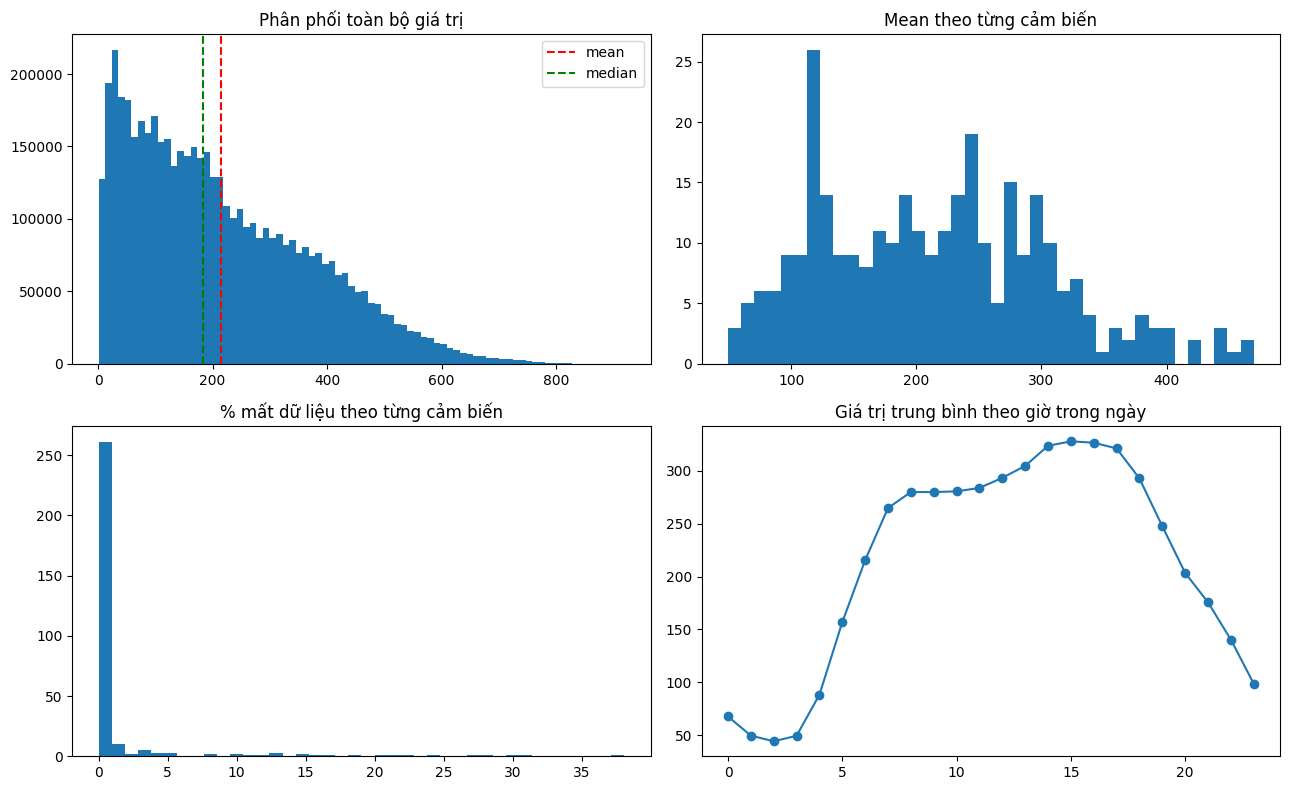

In [6]:
# --- Thống kê mô tả trên toàn bộ giá trị quan sát ---
# Bỏ NaN để chỉ thống kê trên giá trị quan sát được.
obs = VALUES[~np.isnan(VALUES)]
desc = pd.Series({
    "count": obs.size, "mean": obs.mean(), "median": np.median(obs), "std": obs.std(),
    "min": obs.min(), "p5": np.percentile(obs, 5), "p95": np.percentile(obs, 95), "max": obs.max(),
    "skewness": float(((obs - obs.mean()) ** 3).mean() / obs.std() ** 3),
}, name="toàn bộ giá trị quan sát").to_frame()
display(desc)

# --- Thống kê theo từng cảm biến: phân bố và tỉ lệ mất dữ liệu ---
per_sensor = pd.DataFrame({"mean": np.nanmean(VALUES, 0), "median": np.nanmedian(VALUES, 0),
                           "min": np.nanmin(VALUES, 0), "max": np.nanmax(VALUES, 0),
                           "missing_pct": np.isnan(VALUES).mean(0) * 100}, index=df.columns)
display(per_sensor.describe().T)

# --- Bốn biểu đồ kiểm tra trực quan: phân phối, mean theo cảm biến, missing, profile giờ ---
fig, ax = plt.subplots(2, 2, figsize=(13, 8))
cnt, edges = np.histogram(obs, bins=80)
ax[0, 0].bar(edges[:-1], cnt, width=np.diff(edges), align="edge"); ax[0, 0].set_title("Phân phối toàn bộ giá trị")
ax[0, 0].axvline(obs.mean(), c="r", ls="--", label="mean"); ax[0, 0].axvline(np.median(obs), c="g", ls="--", label="median"); ax[0, 0].legend()
ax[0, 1].hist(per_sensor["mean"], bins=40); ax[0, 1].set_title("Mean theo từng cảm biến")
ax[1, 0].hist(per_sensor["missing_pct"], bins=40); ax[1, 0].set_title("% mất dữ liệu theo từng cảm biến")
# Trung bình mọi cảm biến tại từng mốc thời gian, rồi gộp theo giờ trong ngày.
prof = pd.DataFrame({"v": np.nanmean(VALUES, 1)}, index=df.index)
prof = prof.groupby([prof.index.hour]).v.mean()
ax[1, 1].plot(prof.index, prof.values, marker="o"); ax[1, 1].set_title("Giá trị trung bình theo giờ trong ngày")
plt.tight_layout(); plt.show()


## 4. Chia dữ liệu theo thời gian 70 / 10 / 20
Cắt **liền mạch theo thời gian**, sau đó mới tạo cửa sổ (12 bước vào → 3 mốc ra) **bên trong từng tập**, nên không có cửa sổ nào bắc cầu qua ranh giới → các khoảng thời gian thô không chồng lấn. Scaler và giá trị bù (imputer) chỉ học từ **train**.

In [4]:
class SplitData:
    """Một tập con theo thời gian, giữ nguyên NaN để imputer xử lý sau."""
    def __init__(self, values, index, name):
        self.values, self.index, self.name = values, index, name   # values: (T,N) float32, có NaN
    def __len__(self): return len(self.values)

def make_split(values, index, ratios):
    """Cắt liền mạch theo thời gian thành train / val / test.

    Cắt trước rồi mới tạo cửa sổ trong từng tập để không có cửa sổ
    bắc qua ranh giới (tránh rò rỉ giữa các tập).
    """
    # a, b là ranh giới: train [0,a), val [a,b), test [b,T).
    T = len(values); a = int(T * ratios[0]); b = a + int(T * ratios[1])
    parts = [("train", 0, a), ("val", a, b), ("test", b, T)]
    return {n: SplitData(values[s:e].copy(), index[s:e], n) for n, s, e in parts}

# Tạo 3 tập và kiểm tra thứ tự thời gian.
SPLITS = make_split(VALUES, df.index, CFG["SPLIT"])
train_data, val_data, test_data = SPLITS["train"], SPLITS["val"], SPLITS["test"]
for k, s in SPLITS.items():
    print(f"{k:5s} {len(s):6d} bước | {s.index[0]} -> {s.index[-1]} | NaN {np.isnan(s.values).mean()*100:.2f}%")
assert train_data.index[-1] < val_data.index[0] < val_data.index[-1] < test_data.index[0]


train  11894 bước | 2018-01-01 00:00:00 -> 2018-02-11 07:05:00 | NaN 1.67%
val     1699 bước | 2018-02-11 07:10:00 -> 2018-02-17 04:40:00 | NaN 1.60%
test    3399 bước | 2018-02-17 04:45:00 -> 2018-02-28 23:55:00 | NaN 1.30%


## 5. Ma trận kề, scaler, imputer, cửa sổ dữ liệu

**Input (mỗi mẫu):** tensor `(12 bước, 307 cảm biến, 5 kênh)` — kênh 0 = flow đã scale (đã bù NaN), kênh 1 = mask trạng thái (1 = đo thật, 0 = thiếu/bù), kênh 2–4 = sin/cos giờ trong ngày và cờ cuối tuần (tắt bằng `CFG["USE_TOD"]=False` → 2 kênh).
**Output:** bảng `(307 cảm biến, 3 cột)` = flow sau 15', 30', 60'.
- **Ma trận kề PeMS04**: `distance.csv` chỉ có ~340 cạnh nối trực tiếp nên `ADJ_THR = 0` (giữ mọi cạnh, trọng số Gaussian theo khoảng cách).

- **Imputer** (B1): bù NaN bằng *forward-fill* (chỉ dùng quá khứ, không rò rỉ tương lai); chỗ còn trống dùng median train của từng cảm biến.
- **Scaler** (khai báo trong `SCALERS`, thêm scaler khác chỉ cần thêm 1 class): StandardScaler, MinMaxScaler, LogScaler (log1p rồi chuẩn hoá). Tất cả học theo từng cảm biến, chỉ trên train.

In [5]:
# ---------- Ma trận kề ----------
def norm_adj(A):
    """Chuẩn hoá ma trận kề kiểu DCRNN: A_hat = D^{-1/2} (A + I) D^{-1/2}."""
    At = A + np.eye(len(A)); d = At.sum(1); Dm = 1.0 / np.sqrt(d)
    return (Dm[:, None] * At * Dm[None, :]).astype(np.float32)

def build_adjacency(dist, train_values, thr=0.1, knn=8):
    """Xây dựng ma trận kề từ khoảng cách; fallback sang tương quan nếu thiếu dist.

    Tham số:
        dist        : (N,N) khoảng cách đường đi, có thể có inf cho cặp không nối
        train_values: chỉ dùng để tính tương quan dự phòng (không dùng test)
        thr         : ngưỡng cắt cạnh theo trọng số Gaussian
        knn         : số láng giềng cho fallback tương quan

    Trả về:
        A     : ma trận kề (N,N) dạng dense, trọng số >= 0, phần lớn bằng 0
        A_hat : A đã chuẩn hoá để dùng trong GCN
        prox  : ma trận proximity để chọn khu vực gần nhau khi test
    """
    N = train_values.shape[1]
    if dist is not None and dist.shape == (N, N):
        # Gaussian kernel: cạnh càng gần càng mạnh; cặp xa/không nối bị cắt.
        d = dist.astype("float64")
        fin = np.isfinite(d) & (d > 0)
        # sigma = độ lệch chuẩn của các khoảng cách dương hữu hạn, làm thang cho kernel.
        sigma = d[fin].std()
        with np.errstate(all="ignore"):
            A = np.exp(-(d / sigma) ** 2)
        A[~np.isfinite(d)] = 0; A[A < thr] = 0; np.fill_diagonal(A, 0)
        # Đối xứng hoá: nếu dữ liệu chỉ có một chiều thì vẫn coi là cạnh hai chiều.
        A = np.maximum(A, A.T)
        # PROX dùng để chọn "khu vực" cảm biến gần nhau khi giả lập hỏng.
        prox = np.minimum(d, d.T); prox[~np.isfinite(prox)] = 1e9
        src = "khoảng cách đường đi (Gaussian kernel, DCRNN)"
    else:   # dự phòng: tương quan trên train
        # Chỉ dùng train để tránh rò rỉ thông tin từ val/test vào đồ thị.
        v = pd.DataFrame(train_values).ffill().bfill().to_numpy()
        C = np.nan_to_num(np.corrcoef(v.T)); np.fill_diagonal(C, -1)
        A = np.zeros((N, N))
        # Lấy top-k cảm biến tương quan cao nhất; tương quan âm bị cắt về 0.
        for i in range(N):
            nn_ = np.argsort(-C[i])[:knn]; A[i, nn_] = np.maximum(C[i, nn_], 0)
        A = np.maximum(A, A.T)
        prox = 1 - C; np.fill_diagonal(prox, 0)
        src = "tương quan (dự phòng, không có ma trận khoảng cách)"
    print(f"adjacency: {src} | cạnh: {(A > 0).sum()} | độ thưa: {(A > 0).mean():.3f}")
    return A, norm_adj(A), prox

# A_HAT_T là tensor trên GPU để dùng lại cho mọi model GNN/STGCN.
ADJ_RAW, A_HAT, PROX = build_adjacency(DIST, train_data.values, thr=CFG["ADJ_THR"])
A_HAT_T = torch.tensor(A_HAT, device=DEVICE)


adjacency: khoảng cách đường đi (Gaussian kernel, DCRNN) | cạnh: 680 | độ thưa: 0.007


In [6]:
# ---------- Imputer (B1) ----------
def fit_imputer(train_values):
    """Tính median theo từng cảm biến trên train; fallback median toàn cục."""
    med = np.nanmedian(train_values, axis=0)
    g = np.nanmedian(train_values)
    return np.where(np.isnan(med), g, med).astype("float32")

def impute(values, fill):
    """Điền NaN bằng forward-fill (chỉ nhìn quá khứ) rồi median train.

    Forward-fill giữ tính nhân quả: tại thời điểm t không dùng giá trị tương lai.
    """
    arr = pd.DataFrame(values).ffill().to_numpy(copy=True)      # chỉ nhìn về quá khứ
    nan = np.isnan(arr)
    arr[nan] = np.broadcast_to(fill, arr.shape)[nan]
    return arr.astype("float32")

# ---------- Scalers (theo từng cảm biến, fit trên train) ----------
class BaseScaler:
    """Giao diện chung: fit trên train, transform/inverse theo từng cảm biến."""
    name = "base"
    # _p: đưa tham số numpy sang tensor cùng device/dtype với x.
    def _p(self, v, x): return torch.as_tensor(v, device=x.device, dtype=x.dtype)
    def fit(self, x): raise NotImplementedError
    # fwd/inv áp lên trục cuối (..., N). transform_bnh/inverse_bnh nhận (B,N,H),
    # đổi trục để N thành trục cuối, rồi trả lại đúng shape (B,N,H).
    def fwd(self, x): raise NotImplementedError
    def inv(self, z): raise NotImplementedError
    def transform(self, x): return self.fwd(torch.as_tensor(x, dtype=torch.float32))
    def transform_bnh(self, y): return self.fwd(y.transpose(1, 2)).transpose(1, 2)      # (B,N,H)
    def inverse_bnh(self, z): return self.inv(z.transpose(1, 2)).transpose(1, 2)        # (B,N,H)

class StandardScaler(BaseScaler):
    """Chuẩn hoá theo mean/std của từng cảm biến."""
    name = "standard"
    def fit(self, x): self.mu = np.nanmean(x, 0); self.sd = np.nanstd(x, 0) + 1e-6; return self
    def fwd(self, x): return (x - self._p(self.mu, x)) / self._p(self.sd, x)
    def inv(self, z): return z * self._p(self.sd, z) + self._p(self.mu, z)

class MinMaxScaler(BaseScaler):
    """Chuẩn hoá min-max theo từng cảm biến; tham số fit trên train."""
    name = "minmax"
    def fit(self, x): self.mn = np.nanmin(x, 0); self.rg = np.nanmax(x, 0) - self.mn + 1e-6; return self
    def fwd(self, x): return (x - self._p(self.mn, x)) / self._p(self.rg, x)
    def inv(self, z): return z * self._p(self.rg, z) + self._p(self.mn, z)

class LogScaler(BaseScaler):
    """log1p rồi chuẩn hoá; phù hợp dữ liệu lệch (ví dụ flow đêm thấp / ngày cao)."""
    name = "log"
    def fit(self, x):
        lx = np.log1p(np.clip(x, 0, None)); self.mu = np.nanmean(lx, 0); self.sd = np.nanstd(lx, 0) + 1e-6; return self
    def fwd(self, x): return (torch.log1p(x.clamp_min(0)) - self._p(self.mu, x)) / self._p(self.sd, x)
    def inv(self, z): return torch.expm1((z * self._p(self.sd, z) + self._p(self.mu, z)).clamp(-10, 12))

SCALERS = {"standard": StandardScaler, "minmax": MinMaxScaler, "log": LogScaler}   # thêm scaler khác ở đây

# ---------- Đặc trưng thời gian (không phụ thuộc cảm biến, không rò rỉ) ----------
def time_features(index):
    """Tạo sin/cos giờ trong ngày và cờ cuối tuần, shape (T,3).

    Sin/cos giúp các giờ kề nhau (23:55 và 00:05) có biểu diễn gần nhau.
    """
    ang = 2 * np.pi * (index.hour.values * 60 + index.minute.values) / 1440.0
    wk = (index.dayofweek.values >= 5).astype("float32")                 # thứ 7, CN
    return np.stack([np.sin(ang), np.cos(ang), wk], 1).astype("float32")  # (T,3)

# ---------- Cửa sổ trượt trong từng tập ----------
class Windows:
    """Quản lý cửa sổ trượt của một tập; input dùng view để tiết kiệm bộ nhớ.

    Mỗi mẫu lấy từ get():
        x: (C, n_past, N), theo batch là (B, C, n_past, N)
        C = 2 (giá trị scale, mask) hoặc 5 (+ sin/cos giờ, cờ cuối tuần)
        y: (N, H) tại các mốc trong HORIZONS (mặc định +3, +6, +12 bước)
    """
    def __init__(self, split, scaler, fill, n_past, stride=1):
        raw = split.values
        observed = ~np.isnan(raw)
        z = scaler.transform(impute(raw, fill))
        # Kênh 0: giá trị đã scale; kênh 1: mask 1 = quan sát thật, 0 = đã điền.
        x = torch.stack([z, torch.as_tensor(observed, dtype=torch.float32)], -1)               # (T,N,2)
        if CFG["USE_TOD"]:
            # Thêm 3 kênh thời gian, broadcast cho mọi cảm biến.
            tf = torch.as_tensor(time_features(split.index))[:, None, :].expand(-1, x.shape[1], -1)
            x = torch.cat([x, tf], -1)                                                         # (T,N,5)
        x = x.to(DEVICE).contiguous()
        self.n_past = n_past
        # unfold trượt từng bước và trả view, không copy dữ liệu.
        # self.starts bên dưới chọn mẫu dày/thưa theo stride.
        self.xw = x.unfold(0, n_past, 1)                                   # (T-n+1, N, C, n_past) view
        # Nhãn thô (đơn vị gốc: flow xe/5 phút) + mask; NaN thay bằng 0 nhưng mask = 0 nên không vào loss/metric.
        self.y_raw = torch.as_tensor(np.nan_to_num(raw, nan=0.0), dtype=torch.float32, device=DEVICE)
        self.y_mask = torch.as_tensor(observed, device=DEVICE)             # chỉ tính metric trên nhãn thật
        self.h = torch.tensor(HORIZONS, device=DEVICE)
        last = len(raw) - n_past - max(HORIZONS)
        assert last >= 0, "tập quá ngắn"
        self.starts = torch.arange(0, last + 1, stride, device=DEVICE)
    def __len__(self): return len(self.starts)
    def get(self, pos):
        """Lấy batch theo vị trí trong self.starts."""
        s = self.starts[pos]
        xb = self.xw[s].permute(0, 3, 1, 2)                                  # (B,C,n,N)
        # Thời điểm đích = cuối cửa sổ + horizon (3/6/12 bước).
        rows = s[:, None] + self.n_past - 1 + self.h[None, :]                # (B,H)
        yr = self.y_raw[rows].permute(0, 2, 1)                               # (B,N,H)
        ym = self.y_mask[rows].permute(0, 2, 1)
        return xb, yr, ym

def batches(n, bs, shuffle):
    """Sinh chỉ số batch; shuffle dùng random permutation trên GPU."""
    idx = torch.randperm(n, device=DEVICE) if shuffle else torch.arange(n, device=DEVICE)
    for i in range(0, n, bs): yield idx[i:i + bs]


## 6. Mô hình: GRU, GNN (GCN), STGCN (+ baseline "lặp lại giá trị cuối")
Tất cả nhận `x: (B, T, N, C)` (C = 5) và trả `(B, N, 3)`.
- **GRU**: một GRU dùng chung cho mọi cảm biến (không dùng không gian).
- **GNN**: encoder tuyến tính trên cả cửa sổ rồi 2 lớp GCN. Mỗi lớp = đường *tự thân* + đường *láng giềng* (`A @ h`, trọng số khởi tạo 0) + residual + LayerNorm.
- **STGCN**: 2 khối (Conv thời gian GLU → self + láng giềng → Conv thời gian GLU → residual → LayerNorm).
- Cờ `use_adj=False` thay ma trận kề bằng ma trận đơn vị → **loại bỏ thông tin không gian** (thí nghiệm ablation).

- **Dự báo phần chênh** (`CFG["RESIDUAL"]=True`): output = giá trị cuối + phần học được; head khởi tạo 0 ⇒ mọi model bắt đầu đúng bằng persistence.
- **Giữ đường tự thân** trong graph layer: bản đầu chỉ có `A @ h` nên mỗi cảm biến bị trộn với láng giềng ngay từ đầu (over-smoothing). Nhánh láng giềng khởi tạo 0 nên model chỉ dùng không gian khi nó thật sự giúp ích.
- **Bỏ BatchNorm** (thống kê batch lệch khi dữ liệu mất) → LayerNorm theo từng vị trí.
- **Giờ trong ngày / cuối tuần** làm đặc trưng; `EPOCHS` 20 → 40, `PATIENCE` 6 (bản đầu nhiều run chạm trần 20 epoch).


In [7]:
# Số kênh input: giá trị + mask (+ 3 kênh thời gian nếu USE_TOD) (+ 1 kênh ma trận kề nếu USE_ADJ_FEAT).
#   kênh 0: flow đã scale | kênh 1: mask (1 = cảm biến hoạt động bình thường, 0 = mất dữ liệu)
#   kênh 2-4: sin/cos giờ, cờ cuối tuần | kênh cuối: đặc trưng láng giềng từ ma trận kề
N_IN = 2 + (3 if CFG["USE_TOD"] else 0) + (1 if CFG["USE_ADJ_FEAT"] else 0)

# Ma trận kề thô (trọng số Gaussian, đường chéo = 0) dùng để tính đặc trưng láng giềng.
_A_nb = ADJ_RAW.astype("float32").copy(); np.fill_diagonal(_A_nb, 0.0)
A_NB_T = torch.tensor(_A_nb, device=DEVICE)

def add_adj_feature(xb, A_nb):
    """Thêm 1 kênh từ ma trận kề: trung bình có trọng số A của các láng giềng ĐANG HOẠT ĐỘNG.

    xb: (B,T,N,C) với kênh 0 = giá trị, kênh 1 = mask. Gọi SAU inject_fault để cảm biến hỏng
    (mask = 0) không đóng góp vào đặc trưng của láng giềng.
    nb[b,t,n] = Σ_m A[n,m]·mask[m]·v[m] / Σ_m A[n,m]·mask[m]; nếu không có láng giềng hoạt động -> dùng v[n].
    """
    if not CFG["USE_ADJ_FEAT"]: return xb
    v, m = xb[..., 0].float(), xb[..., 1].float()
    num = torch.einsum("nm,btm->btn", A_nb, v * m)
    den = torch.einsum("nm,btm->btn", A_nb, m)
    nb = torch.where(den > 1e-6, num / den.clamp_min(1e-6), v)
    return torch.cat([xb, nb.unsqueeze(-1).to(xb.dtype)], -1)

def _zero_(m):
    """Khởi tạo trọng số/bias bằng 0 để nhánh mới ban đầu không đóng góp."""
    nn.init.zeros_(m.weight)
    if m.bias is not None: nn.init.zeros_(m.bias)
    return m

class BaseNet(nn.Module):
    """Lớp cơ sở: core() sinh phần chênh; forward() cộng giá trị cuối cửa sổ nếu RESIDUAL."""
    def core(self, x): raise NotImplementedError
    def forward(self, x):
        out = self.core(x)                                  # phần chênh so với persistence
        if CFG["RESIDUAL"]: out = out + x[:, -1, :, 0:1]    # neo = giá trị cuối cửa sổ
        return out

class GRUNet(BaseNet):
    """GRU dùng chung cho mọi cảm biến; không khai thác quan hệ không gian."""
    def __init__(self, n_nodes, n_in, n_out, hidden, n_past, A):
        super().__init__()
        self.gru = nn.GRU(n_in, hidden, num_layers=2, batch_first=True, dropout=0.1)
        self.head = _zero_(nn.Linear(hidden, n_out))
    def core(self, x):
        B, T, N, Fd = x.shape
        # Gộp batch và cảm biến để chạy một GRU chung: (B*N, T, C).
        h, _ = self.gru(x.permute(0, 2, 1, 3).reshape(B * N, T, Fd))
        return self.head(h[:, -1]).reshape(B, N, -1)

class GCNNet(BaseNet):
    """GCN nhẹ: self + láng giềng (A@h) + residual + LayerNorm.

    Nhánh láng giềng khởi tạo 0: ban đầu model giống MLP, phần không gian được học dần.
    """
    def __init__(self, n_nodes, n_in, n_out, hidden, n_past, A):
        super().__init__()
        self.register_buffer("A", A)
        self.enc = nn.Linear(n_past * n_in, hidden)
        self.slf = nn.ModuleList([nn.Linear(hidden, hidden) for _ in range(2)])
        self.nbr = nn.ModuleList([_zero_(nn.Linear(hidden, hidden)) for _ in range(2)])
        self.norm = nn.ModuleList([nn.LayerNorm(hidden) for _ in range(2)])
        self.head = _zero_(nn.Linear(hidden, n_out)); self.drop = nn.Dropout(0.1)
    def core(self, x):
        B, T, N, Fd = x.shape
        # Mỗi cảm biến là một vector đặc trưng (T*C) -> hidden.
        h = F.relu(self.enc(x.permute(0, 2, 1, 3).reshape(B, N, T * Fd)))
        for s, g, n in zip(self.slf, self.nbr, self.norm):
            # agg[b,n,:] = tổng có trọng số đặc trưng của các cảm biến láng giềng.
            agg = torch.einsum("nm,bmc->bnc", self.A, h)
            # residual + LayerNorm để ổn định khi xếp 2 lớp.
            h = n(h + self.drop(F.relu(s(h) + g(agg))))
        return self.head(h)

class TemporalGLU(nn.Module):
    """Conv theo trục thời gian + gated linear unit."""
    def __init__(self, cin, cout, k=3):
        super().__init__(); self.conv = nn.Conv2d(cin, 2 * cout, (k, 1), padding=(k // 2, 0))
    def forward(self, x):                                  # x: (B,C,T,N)
        p, q = self.conv(x).chunk(2, 1)                    # nửa giá trị, nửa cổng
        return p * torch.sigmoid(q)                        # GLU: cổng sigmoid quyết định giữ bao nhiêu thông tin

class ChanNorm(nn.Module):
    """LayerNorm theo kênh, áp dụng độc lập cho từng (thời điểm, cảm biến)."""
    def __init__(self, c): super().__init__(); self.ln = nn.LayerNorm(c)
    def forward(self, x):
        # LayerNorm cần kênh ở trục cuối: (B,C,T,N) -> (B,T,N,C) -> lại như cũ.
        return self.ln(x.permute(0, 2, 3, 1)).permute(0, 3, 1, 2)

class STBlock(nn.Module):
    """Một khối STGCN: temporal GLU -> self + láng giềng -> temporal GLU -> cộng skip -> norm."""
    def __init__(self, cin, cmid, cout, A):
        super().__init__()
        self.A = A
        self.t1 = TemporalGLU(cin, cmid)
        self.slf = nn.Conv2d(cmid, cmid, 1); self.nbr = _zero_(nn.Conv2d(cmid, cmid, 1))
        self.t2 = TemporalGLU(cmid, cout); self.norm = ChanNorm(cout)
        self.skip = nn.Conv2d(cin, cout, 1) if cin != cout else nn.Identity()
    def forward(self, x):
        h = self.t1(x)                                     # (B,C,T,N): trộn thời gian
        # Tổng hợp láng giềng theo A; nbr khởi tạo 0 nên ban đầu chỉ dùng self.
        agg = torch.einsum("nm,bctm->bctn", self.A, h)
        h = F.relu(self.slf(h) + self.nbr(agg))            # self + láng giềng
        # Nhánh skip giữ thông tin gốc; norm ổn định đầu ra.
        return self.norm(self.t2(h) + self.skip(x))

class STGCN(BaseNet):
    """Hai khối STBlock; head dự báo H horizon (15/30/60 phút) cho từng cảm biến."""
    def __init__(self, n_nodes, n_in, n_out, hidden, n_past, A):
        super().__init__()
        self.register_buffer("A", A)
        self.b1 = STBlock(n_in, hidden, hidden, self.A); self.b2 = STBlock(hidden, hidden, hidden, self.A)
        self.head = _zero_(nn.Linear(hidden * n_past, n_out))
    def core(self, x):
        # Conv2d cần (B,C,T,N); hai khối ST trộn thời gian + không gian.
        h = self.b2(self.b1(x.permute(0, 3, 1, 2)))        # (B,C,T,N)
        B, C, T, N = h.shape
        # Duỗi (C,T) cho từng cảm biến rồi dự báo H horizon.
        return self.head(h.permute(0, 3, 1, 2).reshape(B, N, C * T))

class PersistenceNet(nn.Module):
    """Baseline: lặp lại giá trị cuối của cửa sổ cho mọi horizon."""
    def __init__(self, n_nodes, n_in, n_out, hidden, n_past, A):
        super().__init__(); self.n_out = n_out
    def forward(self, x):
        # Lấy giá trị cuối cửa sổ (kênh 0) và lặp cho mọi horizon.
        return x[:, -1, :, 0].unsqueeze(-1).repeat(1, 1, self.n_out)

MODELS = {"GRU": GRUNet, "GNN": GCNNet, "STGCN": STGCN, "PERSIST": PersistenceNet}

def build_model(name, n_nodes, n_past, hidden, use_adj=True):
    """Tạo model theo tên; use_adj=False thay A bằng I cho ablation không gian."""
    A = A_HAT_T if use_adj else torch.eye(n_nodes, device=DEVICE)
    m = MODELS[name](n_nodes, N_IN, H, hidden, n_past, A)
    # Ma trận cho kênh đặc trưng láng giềng; ablation (use_adj=False) -> không có láng giềng.
    m.A_nb = A_NB_T if use_adj else torch.zeros(n_nodes, n_nodes, device=DEVICE)
    return m.to(DEVICE)


## 7. Mô phỏng cảm biến hỏng, metric, đánh giá
Khi cảm biến hỏng: **kích thước dữ liệu giữ nguyên, mốc thời gian còn, chỉ giá trị mất**. Với mỗi mẫu, một nhóm cảm biến mất dữ liệu trong `L` bước cuối của cửa sổ (L = 3 → 15 phút, L = 6 → 30 phút). Giá trị bị mất được bù bằng giá trị tốt gần nhất (forward-fill, đúng cách hệ thống thực tế hay làm) và mask = 0.
Metric (MAE, RMSE, MAPE) tính ở **đơn vị gốc**, chỉ trên nhãn thật có đo (không tính chỗ nhãn vốn thiếu).

In [8]:
def inject_fault(xb, L, k=None, sensors=None, gen=None):
    """Giả lập cảm biến hỏng trong L bước cuối của cửa sổ.

    xb: (B,T,N,C). k = số cảm biến hỏng mỗi mẫu (chọn ngẫu nhiên);
    sensors: bool (N,) cố định, dùng cho kịch bản hỏng theo khu vực.
    Giá trị bị mất được thay bằng giá trị ngay trước khi mất và mask = 0.
    """
    B, T, N, _ = xb.shape
    assert T > L, "n_past phải > số bước mất"
    # hit[b,n] = True nghĩa cảm biến n hỏng ở mẫu b.
    if sensors is not None:
        hit = sensors.view(1, N).expand(B, N)
    else:
        if not k: return xb
        # Mỗi mẫu chọn ngẫu nhiên k cảm biến; generator giúp tái lập kịch bản.
        idx = torch.rand(B, N, device=xb.device, generator=gen).topk(k, dim=1).indices
        hit = torch.zeros(B, N, dtype=torch.bool, device=xb.device).scatter_(1, idx, True)
    out = xb.clone()
    tail_v, tail_m = xb[:, T - L:, :, 0], xb[:, T - L:, :, 1]
    last_good = xb[:, T - L - 1, :, 0].unsqueeze(1).expand(B, L, N)
    h3 = hit.unsqueeze(1)
    # Chỉ sửa kênh giá trị và mask; các kênh thời gian giữ nguyên.
    out[:, T - L:, :, 0] = torch.where(h3, last_good, tail_v)
    out[:, T - L:, :, 1] = torch.where(h3, torch.zeros_like(tail_m), tail_m)
    return out

class MetricAcc:
    """Cộng dồn tử số/mẫu số để tính MAE/RMSE/MAPE theo từng horizon; bỏ qua nhãn thiếu."""
    def __init__(self):
        # Cộng dồn: SAE = Σ|e|, SSE = Σe², SAPE = Σ|e|/true; n và nape là số phần tử hợp lệ.
        self.sae = torch.zeros(H, dtype=torch.float64); self.sse = torch.zeros(H, dtype=torch.float64)
        self.sape = torch.zeros(H, dtype=torch.float64); self.n = torch.zeros(H, dtype=torch.float64); self.nape = torch.zeros(H, dtype=torch.float64)
    def add(self, pred, true, mask):
        m = mask.double(); e = (pred - true).double()
        # mask = 1 chỉ tại nhãn thật; nhãn NA không được tính vào metric.
        self.sae += (e.abs() * m).sum((0, 1)).cpu(); self.sse += ((e ** 2) * m).sum((0, 1)).cpu(); self.n += m.sum((0, 1)).cpu()
        # MAPE bỏ qua nhãn <= 1 (flow gần 0 ban đêm) để tránh chia cho số quá nhỏ.
        mm = (mask & (true > 1.0)).double()
        self.sape += ((e.abs() / true.clamp_min(1.0).double()) * mm).sum((0, 1)).cpu(); self.nape += mm.sum((0, 1)).cpu()
    def result(self):
        # MAE/RMSE/MAPE cho từng horizon, rồi lấy trung bình 3 horizon cho *_avg.
        mae = (self.sae / self.n).numpy(); rmse = (self.sse / self.n).sqrt().numpy(); mape = (100 * self.sape / self.nape).numpy()
        out = {}
        for i, mn in enumerate(HOR_MIN):
            out[f"MAE_{mn}"], out[f"RMSE_{mn}"], out[f"MAPE_{mn}"] = float(mae[i]), float(rmse[i]), float(mape[i])
        out["MAE_avg"], out["RMSE_avg"], out["MAPE_avg"] = float(mae.mean()), float(rmse.mean()), float(mape.mean())
        return out

@torch.no_grad()          # đánh giá không cần gradient
def evaluate(model, win, scaler, fault=None, bs=None):
    """Chạy model trên toàn bộ Windows, có thể inject fault trước khi dự báo."""
    bs = int(bs if bs is not None else getattr(model, "eval_bs", CFG.get("EVAL_BATCH", 64)))
    if bs <= 0: raise ValueError("Evaluation batch size must be positive")
    model.eval(); acc = MetricAcc()
    for pos in batches(len(win), bs, False):
        xb, yr, ym = win.get(pos)
        if fault is not None: xb = inject_fault(xb, **fault)
        xb = add_adj_feature(xb, model.A_nb)              # kênh ma trận kề tính sau khi hỏng
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            pred = model(xb)
        # Đưa dự báo về đơn vị gốc (UNIT) trước khi tính metric.
        pred = scaler.inverse_bnh(pred.float()).clamp_min(0)
        if not torch.isfinite(pred).all():
            raise FloatingPointError("Non-finite predictions during evaluation")
        acc.add(pred, yr, ym)
    return acc.result()


## 8. Hàm training `train_model`
Input: `train_data, val_data, test_data, scaler_name, model_name, n_past` (+ tuỳ chọn `mask_aug`, `use_adj`, `epochs`, `seed`).
Các bước: **B1** impute NaN + scale → **B2** tạo model → **B3** train → **B4** validate (mỗi epoch, early stopping) → **B5** test với 0% mất dữ liệu → **B6** trả `(model, train_result, test_result)`. Mỗi lần gọi tự ghi 1 dòng vào bảng `RESULTS`.
Model trả về có gắn sẵn `model.scaler`, `model.fill`, `model.n_past` để hàm test dùng lại. Trên GPU, vòng train và evaluate dùng **AMP FP16** (`CFG["AMP"]=True`) để tận dụng tensor cores của RTX 3060; loss luôn tính bằng FP32. Loss là MAE có mask trên dữ liệu chuẩn hóa, không phải phần trăm. Mỗi epoch in loss, validation MAE/MAPE/RMSE và learning rate. `monitor` chọn MAE hoặc MAPE cho scheduler, checkpoint và early stopping; `evaluate_test=False` dành cho tuning chỉ trên validation.

In [9]:
RESULTS = []      # Mỗi lần train_model ghi một cấu hình; test có thể tắt khi tuning.
ROBUST = []       # Mỗi lần test_model(log=True) ghi một kịch bản mất dữ liệu.

def results_df(): return pd.DataFrame(RESULTS)
def robust_df(): return pd.DataFrame(ROBUST)

def train_model(train_data, val_data, test_data, scaler_name, model_name, n_past,
                mask_aug=0.0, use_adj=True, epochs=None, seed=None, tag="", verbose=True,
                miss_rates=None, hidden=None, lr=None, batch_size=None, eval_bs=None,
                monitor="MAE_avg", evaluate_test=True):
    """Train trên train, chọn checkpoint theo validation; test chỉ chạy khi evaluate_test=True.

    MAE/RMSE có đơn vị gốc; MAPE có đơn vị %. Loss giữ nguyên MAE chuẩn hóa có mask.
    best_train_loss là loss của epoch có checkpoint validation tốt nhất.
    """
    if monitor not in ("MAE_avg", "MAPE_avg"):
        raise ValueError("monitor must be MAE_avg or MAPE_avg")
    seed = CFG["SEED"] if seed is None else int(seed)
    epochs = CFG["EPOCHS"] if epochs is None else int(epochs)
    hidden = CFG["HIDDEN"] if hidden is None else int(hidden)
    lr = CFG["LR"] if lr is None else float(lr)
    batch_size = CFG["BATCH"] if batch_size is None else int(batch_size)
    eval_bs = CFG.get("EVAL_BATCH", 64) if eval_bs is None else int(eval_bs)
    if min(epochs, hidden, batch_size, eval_bs) <= 0 or not np.isfinite(lr) or lr <= 0:
        raise ValueError("epochs, hidden, lr and batch sizes must be positive and finite")
    set_seed(seed); t0 = time.time()
    # Fit imputer/scaler chỉ trên train; giữ nguyên công thức loss trước đây.
    scaler = SCALERS[scaler_name]().fit(train_data.values)
    fill = fit_imputer(train_data.values)
    ls = float(scaler.transform(impute(train_data.values, fill)).std())
    if not np.isfinite(ls) or ls <= 0:
        raise ValueError("Invalid scaled training standard deviation")
    tr = Windows(train_data, scaler, fill, n_past, CFG["TRAIN_STRIDE"])
    va = Windows(val_data, scaler, fill, n_past, 1)
    # Tuning không tạo cửa sổ test và không đánh giá test.
    te = Windows(test_data, scaler, fill, n_past, 1) if evaluate_test else None
    model = build_model(model_name, N_NODES, n_past, hidden, use_adj)
    model.eval_bs = eval_bs
    model.train_config = dict(model=model_name, scaler=scaler_name, n_past=n_past,
                              hidden=hidden, lr=lr, batch_size=batch_size, eval_bs=eval_bs,
                              epochs=epochs, seed=seed, train_stride=CFG["TRAIN_STRIDE"],
                              mask_aug=mask_aug, miss_rates=tuple(miss_rates) if miss_rates else (),
                              use_adj=use_adj, adj_feat=CFG["USE_ADJ_FEAT"],
                              monitor=monitor, evaluate_test=bool(evaluate_test))
    params = [p for p in model.parameters() if p.requires_grad]
    n_params = int(sum(p.numel() for p in params))
    hist = {"train_loss": [], "val_MAE": [], "val_MAPE": [], "val_RMSE": [], "lr": []}
    best_score, best_state, best_epoch = float("inf"), None, 0
    best_val_metrics, best_train_loss = None, None
    if params:
        opt = torch.optim.Adam(params, lr=lr)
        sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=CFG.get("LR_FACTOR", 0.5),
                                                        patience=CFG.get("LR_PATIENCE", 2), min_lr=CFG.get("MIN_LR", 0.0))
        amp_scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
        bad = 0
        for ep in range(1, epochs + 1):
            model.train(); tot, cnt = 0.0, 0
            epoch_lr = float(opt.param_groups[0]["lr"])
            for pos in batches(len(tr), batch_size, True):
                xb, yr, ym = tr.get(pos)
                if miss_rates:
                    rate = float(np.random.choice(miss_rates))
                    k = int(round(rate * N_NODES))
                    if k > 0: xb = inject_fault(xb, L=int(np.random.choice([3, 6])), k=k)
                elif mask_aug > 0:
                    k = int(round(np.random.rand() * mask_aug * N_NODES))
                    if k > 0: xb = inject_fault(xb, L=int(np.random.choice([3, 6])), k=k)
                xb = add_adj_feature(xb, model.A_nb)
                yz = scaler.transform_bnh(yr)
                opt.zero_grad(set_to_none=True)
                with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
                    pred = model(xb)
                loss = (F.l1_loss(pred.float() / ls, yz / ls, reduction="none") * ym).sum() / ym.sum().clamp_min(1)
                if not torch.isfinite(loss):
                    raise FloatingPointError(f"Non-finite loss at epoch {ep}")
                amp_scaler.scale(loss).backward()
                amp_scaler.unscale_(opt)
                nn.utils.clip_grad_norm_(params, 5.0)
                amp_scaler.step(opt); amp_scaler.update()
                valid_count = int(ym.sum().item())
                tot += float(loss.detach().item()) * valid_count; cnt += valid_count
            if cnt == 0:
                raise ValueError("Training windows have no observed targets")
            epoch_loss = tot / cnt
            val_metrics = evaluate(model, va, scaler)
            if not all(np.isfinite(v) for v in val_metrics.values()):
                raise FloatingPointError(f"Non-finite validation metrics at epoch {ep}")
            score = val_metrics[monitor]
            hist["train_loss"].append(epoch_loss)
            for metric in ("MAE", "MAPE", "RMSE"):
                hist[f"val_{metric}"].append(val_metrics[f"{metric}_avg"])
            hist["lr"].append(epoch_lr)
            sched.step(score)
            if verbose:
                print(f"  [{model_name}/{scaler_name}{tag}] ep {ep:03d} loss {epoch_loss:.4f} "
                      f"val_MAE {val_metrics['MAE_avg']:.3f} val_MAPE {val_metrics['MAPE_avg']:.3f}% "
                      f"val_RMSE {val_metrics['RMSE_avg']:.3f} lr {epoch_lr:.2g}", flush=True)
            if score < best_score:
                best_score = score
                best_state = {k: v.clone() for k, v in model.state_dict().items()}
                best_epoch, best_train_loss = ep, epoch_loss
                best_val_metrics = val_metrics.copy(); bad = 0
            else:
                bad += 1
                if bad >= CFG["PATIENCE"]: break
        if best_state is None:
            raise RuntimeError("Training produced no valid validation checkpoint")
        model.load_state_dict(best_state)
    else:
        best_val_metrics = evaluate(model, va, scaler)
        if not all(np.isfinite(v) for v in best_val_metrics.values()):
            raise FloatingPointError("Non-finite baseline validation metrics")
        best_score = best_val_metrics[monitor]
    test_res = evaluate(model, te, scaler) if evaluate_test else {}
    train_res = {"best_val_MAE": best_val_metrics["MAE_avg"],
                 "best_val_MAPE": best_val_metrics["MAPE_avg"],
                 "best_val_RMSE": best_val_metrics["RMSE_avg"],
                 "best_train_loss": best_train_loss, "best_val_metrics": best_val_metrics,
                 "best_epoch": best_epoch, "epochs_run": len(hist["train_loss"]),
                 "n_params": n_params, "train_time_s": time.time() - t0,
                 "monitor": monitor, "best_monitor": best_score, "history": hist}
    model.scaler, model.fill, model.n_past, model.name_ = scaler, fill, n_past, model_name
    RESULTS.append(dict(model.train_config, miss_rates=str(tuple(miss_rates)) if miss_rates else "",
                        tag=tag, n_params=n_params, best_epoch=best_epoch,
                        train_time_s=round(train_res["train_time_s"], 1),
                        val_MAE=best_val_metrics["MAE_avg"], val_MAPE=best_val_metrics["MAPE_avg"],
                        val_RMSE=best_val_metrics["RMSE_avg"], train_loss=best_train_loss,
                        **{f"test_{k}": v for k, v in test_res.items()}))
    return model, train_res, test_res


## 9. Hàm testing `test_model`
Input: `test_data, scaler, model, miss_pct (% cảm biến mất), miss_minutes (số phút mất)`; mở rộng: `region` (mảng chỉ số cảm biến cố định → hỏng theo khu vực), `n_rep` (lặp ngẫu nhiên lấy trung bình).
`miss_pct = 0` ⇒ test sạch.

In [10]:
def get_region(center, k):
    """Lấy k cảm biến gần tâm `center` nhất theo PROX (đường đi hoặc tương quan)."""
    return np.argsort(PROX[center])[:k]

def _avg(dicts):
    """Trung bình cộng từng metric trong danh sách kết quả (khi chạy lặp nhiều lần)."""
    return {k: float(np.mean([d[k] for d in dicts])) for k in dicts[0]}

def test_model(test_data, scaler, model, miss_pct=0, miss_minutes=0, region=None, n_rep=None,
               seed=0, label=None, scenario=None, log=True):
    """Đánh giá một model dưới kịch bản mất cảm biến.

    miss_pct     : % cảm biến bị mất (chọn ngẫu nhiên mỗi mẫu)
    miss_minutes : số phút mất ở cuối cửa sổ (15/30 phút)
    region       : danh sách chỉ số cảm biến cố định (hỏng theo khu vực)
    n_rep        : số lần lặp ngẫu nhiên, lấy trung bình
    seed         : seed gốc cho các lần lặp ngẫu nhiên
    label        : tên model ghi vào ROBUST (mặc định lấy model.name_)
    scenario     : nhãn kịch bản ghi vào ROBUST

    Nếu log=True, mỗi lần gọi ghi thêm một dòng vào ROBUST.
    """
    n_rep = n_rep or CFG["N_REP"]; n_past = model.n_past
    win = Windows(test_data, scaler, model.fill, n_past, 1)
    L = int(miss_minutes // CFG["STEP_MIN"])          # số bước 5 phút bị mất
    if region is None and (miss_pct == 0 or L == 0):
        # Test sạch: không can thiệp vào input.
        res = evaluate(model, win, scaler); k = 0
    elif region is not None:
        # Hỏng cố định theo khu vực: cùng một tập cảm biến cho mọi mẫu.
        sens = torch.zeros(N_NODES, dtype=torch.bool, device=DEVICE); sens[torch.as_tensor(region, device=DEVICE)] = True
        res = evaluate(model, win, scaler, fault=dict(L=L, sensors=sens)); k = len(region)
    else:
        # Hỏng ngẫu nhiên: lặp n_rep lần với seed khác nhau rồi lấy trung bình.
        k = int(round(miss_pct / 100 * N_NODES)); outs = []
        for r in range(n_rep):
            g = torch.Generator(device=DEVICE); g.manual_seed(seed * 1000 + r)
            outs.append(evaluate(model, win, scaler, fault=dict(L=L, k=k, gen=g)))
        res = _avg(outs)
    # Ghi một dòng vào ROBUST để cuối notebook pivot thành bảng.
    if log:
        ROBUST.append(dict(model=label or getattr(model, "name_", "model"), scenario=scenario or ("region" if region is not None else "random"),
                           miss_pct=miss_pct, miss_minutes=miss_minutes, n_sensors_lost=k, **res))
    return res


### Theo dõi tuning và phân biệt metric

MAE/RMSE tính bằng **xe/5 phút**; MAPE tính bằng **%**, bỏ nhãn thiếu và nhãn `<= 1`. Loss là MAE trên dữ liệu chuẩn hóa, nên mục tiêu loss `0.05` và MAPE `11–12%` là hai mục tiêu riêng, không bảo đảm đạt được. Output đã lưu trước khi chỉnh code có test MAPE `14.455%` cho STGCN/standard; đó là mốc tham khảo cũ.

`tune_models.py` quét **18 cấu hình model × scaler × augmentation**, tinh chỉnh **8 cấu hình**, rồi train lại **2 ứng viên** trên mọi cửa sổ, tối đa 100 epoch. Quá trình có thể kéo dài vài giờ trên GPU laptop. Chỉ validation MAPE được dùng chọn cấu hình; test chỉ dùng cho model cuối. Script lưu trial/checkpoint để tiếp tục khi chạy lại cùng code và dữ liệu.

Cell dưới chỉ đọc tiến độ từ lần chạy `staged-*` mới nhất, không tự khởi chạy sweep. Chạy lại cell để cập nhật bảng; lệnh in bên dưới dùng đúng Python của kernel. Các thư mục `smoke-*` là kiểm tra nhỏ và không được hiển thị như kết quả tuning thật.


In [ ]:
# Xem tiến độ tuning; chạy lệnh in bên dưới trong terminal để bắt đầu/tiếp tục.
import json as _tuning_json
_tuning_root = PROJECT_DIR / "outputs" / "tuning"
_manifests = list(_tuning_root.glob("staged-*/manifest.json")) if _tuning_root.exists() else []
if _manifests:
    _tuning_dir = max(_manifests, key=lambda p: p.stat().st_mtime).parent
    print("Kết quả tuning:", _tuning_dir)
    _trial_csv = _tuning_dir / "trials.csv"
    if _trial_csv.exists():
        _trials = pd.read_csv(_trial_csv)
        _show_cols = [c for c in ["stage", "trial_id", "status", "model", "scaler", "augmentation",
                                  "n_past", "hidden", "lr", "best_epoch", "best_train_loss",
                                  "val_MAE", "val_MAPE", "val_RMSE"] if c in _trials.columns]
        display(_trials[_show_cols].round(4))
    _final_path = _tuning_dir / "final_result.json"
    if _final_path.exists():
        _final_result = _tuning_json.loads(_final_path.read_text(encoding="utf-8"))
        print("Kết quả model cuối (test chỉ sau khi chọn bằng validation):")
        display(pd.Series(_final_result["test"], name="test"))
        print("Mục tiêu đã đạt:", _final_result.get("target_met", {}))
    else:
        print("Chưa có kết quả test cuối; xem trials.csv và log terminal để theo dõi.")
else:
    print("Chưa có lần tuning thật trong outputs/tuning/staged-*.")
import subprocess as _tuning_subprocess
print("Lệnh chạy trong terminal:")
print(_tuning_subprocess.list2cmdline([sys.executable, "-u", str(PROJECT_DIR / "tune_models.py"), "--run"]))


### Thử nghiệm mới: đổi input và model, giữ nguyên cách tính

Các cell mới nằm ngay dưới mục này. Chỉ thay đầu vào và kiến trúc; vẫn dự báo flow ở 15/30/60 phút trên cùng split 70/10/20.

- **Input (`EXPERIMENT_INPUTS_V2`)**: tùy chọn thêm occupancy và speed trong cửa sổ quá khứ. Imputer/mean/std chỉ fit trên train; không dùng covariate tương lai.
- **Model (`EXPERIMENT_MODELS_V2`)**: thêm `STID` với embedding cảm biến/giờ/cuối tuần; thêm `GNN_ADAPT` với graph vật lý và graph học từ dữ liệu train. Các model cũ giữ nguyên.
- **Tham số (`EXPERIMENT_SEARCH_V2`)**: sửa danh sách `EXPERIMENTS_V2` để đổi model, scaler, `n_past`, hidden, learning rate, `use_exog`. Lượt này dùng cửa sổ 12/24, hidden 64/96/128, batch 32, tối đa 100 epoch, stride 1, không mask augmentation. Scheduler đợi 5 epoch, early stopping đợi 15 epoch.
- **Chạy thật (`EXPERIMENT_RUN_V2`)**: chạy 6 cấu hình trên CUDA, chọn bằng validation MAPE rồi mới test model cuối. Lưu lịch sử/checkpoint ở `outputs/notebook_v2/search-*`. Có thể chạy lại để tiếp tục các lượt đã hoàn thành.

Công thức loss chuẩn hóa, `MetricAcc`, `evaluate`, ngưỡng MAPE > 1, mask nhãn, scaler đích và các horizon không thay đổi. Mục tiêu MAPE 11–12% và loss 0.05 được báo theo kết quả thật, không cam kết đạt. Cell kiểm tra nhỏ dùng dữ liệu thật ít mẫu, không dùng làm kết quả chất lượng.


In [11]:
# EXPERIMENT_INPUTS_V2
# Chỉ bổ sung dữ liệu quá khứ; nhãn flow, các horizon, loss và metric giữ nguyên.
import hashlib as _v2_hashlib
import json as _v2_json
import gc as _v2_gc

_V2_BASE_WINDOWS = getattr(Windows, "_v2_original", Windows)
_V2_EXOG_FRAME = None
_V2_EXOG_FILL = _V2_EXOG_MEAN = _V2_EXOG_STD = None
if DATASET == "PEMS04":
    _v2_npz = next(Path(CFG["DATA_DIR"]).rglob(DATASETS[DATASET]["main_file"]))
    with np.load(_v2_npz) as _v2_archive:
        _v2_exog = _v2_archive["data"][:, :, 1:3].astype("float32")
    if _v2_exog.shape[:2] != raw_df.shape or _v2_exog.shape[2] != 2:
        raise ValueError("Occupancy/speed không khớp dữ liệu flow")
    _v2_exog[~np.isfinite(_v2_exog) | (_v2_exog < 0)] = np.nan
    _V2_EXOG_FRAME = pd.DataFrame(_v2_exog.reshape(len(raw_df), -1), index=raw_df.index)
    # Mọi thống kê chỉ fit trên các timestamp thuộc train.
    _v2_exog_train = _V2_EXOG_FRAME.reindex(train_data.index).to_numpy()
    _V2_EXOG_FILL = np.nanmedian(_v2_exog_train, axis=0).astype("float32")
    _V2_EXOG_FILL = np.nan_to_num(_V2_EXOG_FILL, nan=0.0)
    _v2_exog_train = impute(_v2_exog_train, _V2_EXOG_FILL)
    _V2_EXOG_MEAN = _v2_exog_train.mean(axis=0)
    _V2_EXOG_STD = np.maximum(_v2_exog_train.std(axis=0), 1e-6)
    del _v2_exog, _v2_exog_train


class Windows(_V2_BASE_WINDOWS):
    """Cửa sổ gốc, tùy chọn thêm occupancy/speed cùng cửa sổ quá khứ."""
    def __init__(self, split, scaler, fill, n_past, stride=1):
        super().__init__(split, scaler, fill, n_past, stride)
        self.exog_windows = None
        if CFG.get("USE_EXOG", False):
            if _V2_EXOG_FRAME is None:
                raise ValueError("USE_EXOG hiện chỉ hỗ trợ PeMS04 có đủ 3 kênh")
            if not split.index.isin(_V2_EXOG_FRAME.index).all():
                raise ValueError("Timestamp input bổ sung không khớp tập dữ liệu")
            raw = _V2_EXOG_FRAME.reindex(split.index).to_numpy()
            # Forward-fill riêng trong split, không lấy dữ liệu tương lai.
            z = (impute(raw, _V2_EXOG_FILL) - _V2_EXOG_MEAN) / _V2_EXOG_STD
            z = torch.as_tensor(z.reshape(len(split), N_NODES, 2), dtype=torch.float32, device=DEVICE)
            self.exog_windows = z.unfold(0, n_past, 1)

    def get(self, pos):
        xb, yr, ym = super().get(pos)
        if self.exog_windows is not None:
            extra = self.exog_windows[self.starts[pos]].permute(0, 3, 1, 2)
            xb = torch.cat([xb, extra], dim=-1)
        return xb, yr, ym


Windows._v2_original = _V2_BASE_WINDOWS


def configure_inputs_v2(use_exog):
    """Đặt số kênh trước khi tạo model; không đổi biến đích hoặc horizon."""
    global N_IN
    CFG["USE_EXOG"] = bool(use_exog)
    N_IN = 2 + (3 if CFG["USE_TOD"] else 0) + (1 if CFG["USE_ADJ_FEAT"] else 0) + (2 if use_exog else 0)


configure_inputs_v2(False)
print("Input thử nghiệm sẵn sàng: flow/mask/thời gian; tùy chọn occupancy/speed quá khứ.")


Input thử nghiệm sẵn sàng: flow/mask/thời gian; tùy chọn occupancy/speed quá khứ.


In [12]:
# EXPERIMENT_MODELS_V2
# Cell mở rộng mô hình: chạy sau cell định nghĩa BaseNet, MODELS và build_model.
# Giữ nguyên input, target, scaler, residual, loss và cách tính metric hiện có.

class _V2Context(nn.Module):
    """Mã hóa cửa sổ, danh tính cảm biến và thời gian ở cuối cửa sổ."""
    def __init__(self, n_nodes, n_in, hidden, n_past):
        super().__init__()
        self.n_nodes = int(n_nodes)
        self.emb_dim = int(CFG.get("NODE_EMB", 16))
        self.use_time = bool(CFG.get("USE_TOD", True))
        if self.emb_dim < 1:
            raise ValueError("NODE_EMB phải là số nguyên dương")
        if self.use_time and n_in < 5:
            raise ValueError("Embedding thời gian cần các kênh sin/cos/cuối tuần ở vị trí 2/3/4")
        self.past = nn.Linear(n_past * n_in, hidden)
        self.node = nn.Embedding(n_nodes, self.emb_dim)
        self.tod = nn.Embedding(288, self.emb_dim)
        self.weekend = nn.Embedding(2, self.emb_dim)
        for embedding in (self.node, self.tod, self.weekend):
            nn.init.normal_(embedding.weight, mean=0.0, std=0.02)
        self.width = hidden + 3 * self.emb_dim

    def forward(self, x):
        batch, steps, nodes, channels = x.shape
        if nodes != self.n_nodes:
            raise ValueError("Số cảm biến của input không khớp mô hình")
        past = F.gelu(self.past(x.permute(0, 2, 1, 3).reshape(batch, nodes, steps * channels)))
        node = self.node.weight.unsqueeze(0).expand(batch, -1, -1)
        if self.use_time:
            # Tái dựng slot 5 phút từ sin/cos đã có; không đọc thời điểm tương lai.
            sin_t = x[:, -1, 0, 2].float()
            cos_t = x[:, -1, 0, 3].float()
            angle = torch.remainder(torch.atan2(sin_t, cos_t), 2 * math.pi)
            slots = torch.round(angle * (288 / (2 * math.pi))).long().remainder(288)
            weekend = x[:, -1, 0, 4].float().round().long().clamp(0, 1)
            time = self.tod(slots).unsqueeze(1).expand(-1, nodes, -1)
            week = self.weekend(weekend).unsqueeze(1).expand(-1, nodes, -1)
        else:
            time = past.new_zeros(batch, nodes, self.emb_dim)
            week = past.new_zeros(batch, nodes, self.emb_dim)
        return torch.cat([past, node.to(past.dtype), time.to(past.dtype), week.to(past.dtype)], dim=-1)


class _V2ResidualMLP(nn.Module):
    """Khối MLP có chuẩn hóa, dropout và đường residual."""
    def __init__(self, width, dropout):
        super().__init__()
        self.norm = nn.LayerNorm(width)
        self.first = nn.Linear(width, 2 * width)
        self.second = nn.Linear(2 * width, width)
        self.drop = nn.Dropout(dropout)

    def forward(self, x):
        h = self.drop(F.gelu(self.first(self.norm(x))))
        return x + self.drop(self.second(h))


class STIDNet(BaseNet):
    """MLP thời gian có embedding cảm biến, giờ trong ngày và cuối tuần."""
    def __init__(self, n_nodes, n_in, n_out, hidden, n_past, A):
        super().__init__()
        depth = int(CFG.get("MODEL_DEPTH", 3))
        dropout = float(CFG.get("DROPOUT", 0.05))
        if depth < 1 or not 0 <= dropout < 1:
            raise ValueError("MODEL_DEPTH >= 1 và 0 <= DROPOUT < 1")
        self.context = _V2Context(n_nodes, n_in, hidden, n_past)
        self.blocks = nn.Sequential(*[_V2ResidualMLP(self.context.width, dropout) for _ in range(depth)])
        self.head = _zero_(nn.Linear(self.context.width, n_out))
        self.use_adj = True
        self.model_options = dict(hidden=hidden, n_past=n_past, node_emb=self.context.emb_dim,
                                  tod_slots=288, weekend_slots=2, use_time=self.context.use_time,
                                  depth=depth, dropout=dropout, use_adj=True)

    def core(self, x):
        return self.head(self.blocks(self.context(x)))


class _V2GraphBlock(nn.Module):
    """Ba đường riêng: cảm biến hiện tại, graph vật lý và graph học được."""
    def __init__(self, hidden, dropout):
        super().__init__()
        self.norm = nn.LayerNorm(hidden)
        self.self_path = nn.Linear(hidden, hidden)
        # Nhánh láng giềng bắt đầu ở 0, rồi học mức đóng góp từ dữ liệu train.
        self.physical_path = _zero_(nn.Linear(hidden, hidden, bias=False))
        self.adaptive_path = _zero_(nn.Linear(hidden, hidden, bias=False))
        self.drop = nn.Dropout(dropout)

    def forward(self, h, physical, adaptive):
        normalized = self.norm(h)
        own = self.self_path(normalized)
        physical_h = torch.einsum("nm,bmc->bnc", physical.to(normalized.dtype), normalized)
        out = own + self.physical_path(physical_h)
        if adaptive is not None:
            adaptive_h = torch.einsum("nm,bmc->bnc", adaptive.to(normalized.dtype), normalized)
            out = out + self.adaptive_path(adaptive_h)
        return h + self.drop(F.gelu(out))


class AdaptiveGCNNet(BaseNet):
    """GNN có embedding ngữ cảnh, graph vật lý và quan hệ thích nghi."""
    def __init__(self, n_nodes, n_in, n_out, hidden, n_past, A):
        super().__init__()
        depth = int(CFG.get("MODEL_DEPTH", 3))
        dropout = float(CFG.get("DROPOUT", 0.05))
        self.topk = int(CFG.get("ADAPT_TOPK", 0))
        if depth < 1 or not 0 <= dropout < 1 or self.topk < 0:
            raise ValueError("Cần MODEL_DEPTH >= 1, 0 <= DROPOUT < 1 và ADAPT_TOPK >= 0")
        self.context = _V2Context(n_nodes, n_in, hidden, n_past)
        self.project = nn.Linear(self.context.width, hidden)
        self.register_buffer("A", A.detach().clone())
        self.adaptive_source = nn.Parameter(torch.randn(n_nodes, self.context.emb_dim) * 0.1)
        self.adaptive_target = nn.Parameter(torch.randn(n_nodes, self.context.emb_dim) * 0.1)
        self.blocks = nn.ModuleList([_V2GraphBlock(hidden, dropout) for _ in range(depth)])
        self.head = _zero_(nn.Linear(hidden, n_out))
        self.use_adj = True
        self.model_options = dict(hidden=hidden, n_past=n_past, node_emb=self.context.emb_dim,
                                  tod_slots=288, weekend_slots=2, use_time=self.context.use_time,
                                  depth=depth, dropout=dropout, adaptive_topk=self.topk, use_adj=True)

    def adaptive_support(self):
        # Tính softmax ở FP32 kể cả khi forward chạy AMP, tránh mất ổn định số.
        nodes = self.adaptive_source.shape[0]
        with torch.autocast(device_type=self.adaptive_source.device.type, enabled=False):
            if nodes == 1:
                return self.adaptive_source.new_zeros((1, 1), dtype=torch.float32)
            scores = F.relu(self.adaptive_source.float() @ self.adaptive_target.float().T
                            / math.sqrt(self.context.emb_dim))
            diagonal = torch.eye(nodes, device=scores.device, dtype=torch.bool)
            scores = scores.masked_fill(diagonal, float("-inf"))
            # Mặc định dùng graph dense; chỉ giới hạn top-k khi cấu hình yêu cầu.
            if 0 < self.topk < nodes - 1:
                indices = scores.topk(self.topk, dim=-1).indices
                selected = torch.zeros_like(scores, dtype=torch.bool).scatter_(1, indices, True)
                scores = scores.masked_fill(~selected, float("-inf"))
            return torch.softmax(scores, dim=-1)

    def core(self, x):
        h = F.gelu(self.project(self.context(x)))
        adaptive = self.adaptive_support() if self.use_adj else None
        for block in self.blocks:
            h = block(h, self.A, adaptive)
        return self.head(h)


MODELS.update({"STID": STIDNet, "GNN_ADAPT": AdaptiveGCNNet})

# Bọc factory một lần; chạy lại cell vẫn gọi đúng factory gốc, tránh đệ quy.
_build_model_v2_original = getattr(build_model, "_v2_original", build_model)


def build_model(name, n_nodes, n_past, hidden, use_adj=True):
    model = _build_model_v2_original(name, n_nodes, n_past, hidden, use_adj=use_adj)
    if isinstance(model, (STIDNet, AdaptiveGCNNet)):
        model.use_adj = bool(use_adj)
        model.model_options["use_adj"] = bool(use_adj)
    return model


build_model._v2_original = _build_model_v2_original


In [13]:
# EXPERIMENT_SEARCH_V2
# Chạy trên toàn bộ train với stride=1. Chọn bằng validation MAPE, chỉ test model cuối.
EXPERIMENTS_V2 = [
    dict(name="stid-node-time", model="STID", scaler="log", n_past=12, hidden=128, lr=1e-3, use_exog=False),
    dict(name="stid-exog-24", model="STID", scaler="log", n_past=24, hidden=128, lr=1e-3, use_exog=True),
    dict(name="adaptive-exog", model="GNN_ADAPT", scaler="log", n_past=12, hidden=96, lr=1e-3, use_exog=True),
    dict(name="gnn-exog-24", model="GNN", scaler="log", n_past=24, hidden=128, lr=1e-3, use_exog=True),
    dict(name="stgcn-clean", model="STGCN", scaler="log", n_past=12, hidden=64, lr=1e-3, use_exog=False),
    dict(name="stgcn-exog", model="STGCN", scaler="log", n_past=12, hidden=64, lr=1e-3, use_exog=True),
]


def _v2_write_json(path, value):
    temp = path.with_suffix(path.suffix + ".tmp")
    temp.write_text(_v2_json.dumps(value, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")
    temp.replace(path)


def run_experiments_v2(plan=None, epoch_budget=100, smoke=False):
    """Thử tham số và kiến trúc, lưu checkpoint và kết quả thật ngay trong notebook."""
    if DEVICE.type != "cuda":
        raise RuntimeError("Thử nghiệm này cần kernel CUDA: Intel Deep Learning (GPU)")
    if CFG["FAST"] or CFG["SYNTHETIC"]:
        raise ValueError("Chỉ dùng dữ liệu thật, FAST=False, SYNTHETIC=False")
    plan = EXPERIMENTS_V2 if plan is None else plan
    original = CFG.copy()
    # Đây là tham số tối ưu hóa; công thức loss/metric không đổi.
    shared = dict(EPOCHS=epoch_budget, PATIENCE=15, TRAIN_STRIDE=1, NODE_EMB=16,
                  MODEL_DEPTH=3, DROPOUT=0.05, LR_PATIENCE=5, LR_FACTOR=0.5, MIN_LR=1e-5)
    _sources = ["".join(c.get("source", [])) for c in _v2_json.loads((PROJECT_DIR / "build_model.ipynb").read_text(encoding="utf-8"))["cells"]]
    _relevant = [s for s in _sources if any(k in s for k in
                 ("class MetricAcc:", "def train_model(", "class STGCN(", "class BaseScaler", "def build_adjacency(",
                  "# EXPERIMENT_INPUTS_V2", "# EXPERIMENT_MODELS_V2", "# EXPERIMENT_SEARCH_V2"))]
    manifest = dict(plan=plan, shared=shared, original_config=original, smoke=smoke,
                    source_hash=_v2_hashlib.sha256("\n".join(_relevant).encode()).hexdigest(),
                    data_hash=_v2_hashlib.sha256(Path(_v2_npz).read_bytes()).hexdigest())
    fingerprint = _v2_hashlib.sha256(_v2_json.dumps(manifest, sort_keys=True).encode()).hexdigest()[:12]
    directory = OUTPUT_DIR / "notebook_v2" / (("smoke-" if smoke else "search-") + fingerprint)
    directory.mkdir(parents=True, exist_ok=True)
    _v2_write_json(directory / "manifest.json", manifest)
    results_path = directory / "trials.json"
    rows = _v2_json.loads(results_path.read_text(encoding="utf-8")) if results_path.exists() else []

    def persist():
        _v2_write_json(results_path, rows)
        flat = [{**r["config"], **{k: v for k, v in r.items() if k not in ("config", "history")}} for r in rows]
        if flat:
            pd.DataFrame(flat).to_csv(directory / "trials.csv", index=False)

    print("GPU:", torch.cuda.get_device_name(0), "| Kết quả:", directory, flush=True)
    try:
        CFG.update(shared)
        for trial in plan:
            config = {**trial, "epochs": epoch_budget, "seed": 42, "batch_size": 32, "eval_bs": 32, **shared}
            trial_id = _v2_hashlib.sha256(_v2_json.dumps(config, sort_keys=True).encode()).hexdigest()[:12]
            checkpoint = directory / f"{trial_id}.pt"
            previous = next((r for r in rows if r["trial_id"] == trial_id), None)
            if previous and previous["status"] == "ok" and checkpoint.exists():
                print(f"Đã có {trial['name']}: val_MAPE {previous['val_MAPE']:.3f}%", flush=True)
                continue
            if previous:
                rows.remove(previous)
            row = dict(trial_id=trial_id, config=config, status="running")
            rows.append(row); persist()
            configure_inputs_v2(trial["use_exog"])
            print(f"\nTHỬ {trial['name']} | {trial} | N_IN={N_IN}", flush=True)
            model = result = None
            started = time.time()
            try:
                tr, va = train_data, val_data
                if smoke:
                    tr = SplitData(tr.values[:512], tr.index[:512], "smoke_train")
                    va = SplitData(va.values[:256], va.index[:256], "smoke_val")
                model, result, test_result = train_model(
                    tr, va, test_data, trial["scaler"], trial["model"], trial["n_past"],
                    hidden=trial["hidden"], lr=trial["lr"], batch_size=32, eval_bs=32,
                    epochs=epoch_budget, seed=42, miss_rates=None, use_adj=True,
                    monitor="MAPE_avg", evaluate_test=False, tag=f"+v2-{trial['name']}", verbose=True)
                assert test_result == {}, "Tuning không được đánh giá test"
                row.update(status="ok", val_MAE=result["best_val_MAE"], val_MAPE=result["best_val_MAPE"],
                           val_RMSE=result["best_val_RMSE"], best_train_loss=result["best_train_loss"],
                           min_train_loss=min(result["history"]["train_loss"]), best_epoch=result["best_epoch"],
                           epochs_run=result["epochs_run"], n_params=result["n_params"], history=result["history"],
                           checkpoint=checkpoint.name, n_in=N_IN)
                # Chỉ lưu trọng số và tiền xử lý; không pickle lớp model của notebook.
                state = dict(state_dict={k: v.detach().cpu() for k, v in model.state_dict().items()},
                             scaler_state=model.scaler.__dict__, fill=model.fill, config=config,
                             input_flags={k: CFG.get(k) for k in ("USE_EXOG", "USE_TOD", "USE_ADJ_FEAT", "RESIDUAL")})
                torch.save(state, checkpoint)
                print(f"XONG {trial['name']}: loss {row['best_train_loss']:.4f}, val_MAE {row['val_MAE']:.3f}, val_MAPE {row['val_MAPE']:.3f}%", flush=True)
            except Exception as exc:
                row.update(status="failed", error=f"{type(exc).__name__}: {exc}")
                print(f"LỖI {trial['name']}: {row['error']}", flush=True)
            finally:
                row["elapsed_s"] = round(time.time() - started, 2)
                persist()
                del model, result
                _v2_gc.collect(); torch.cuda.empty_cache()
        good = sorted((r for r in rows if r["status"] == "ok"), key=lambda r: (r["val_MAPE"], r["val_MAE"]))
        if not good:
            raise RuntimeError("Không có lượt thành công; xem trials.json")
        display(pd.DataFrame([{**r["config"], **{k: r[k] for k in ("best_train_loss", "val_MAE", "val_MAPE", "val_RMSE", "best_epoch")}} for r in good]))
        if smoke:
            print("Kiểm tra nhỏ hoàn tất; không dùng kết quả này để kết luận chất lượng.")
            return directory
        winner = good[0]
        final_path = directory / "final_result.json"
        if final_path.exists():
            final = _v2_json.loads(final_path.read_text(encoding="utf-8"))
        else:
            state = torch.load(directory / winner["checkpoint"], map_location="cpu", weights_only=False)
            config = state["config"]
            CFG.update(shared); CFG.update(state["input_flags"])
            configure_inputs_v2(config["use_exog"])
            model = build_model(config["model"], N_NODES, config["n_past"], config["hidden"], use_adj=True)
            model.load_state_dict(state["state_dict"])
            scaler = SCALERS[config["scaler"]](); scaler.__dict__.update(state["scaler_state"])
            model.scaler, model.fill, model.n_past, model.eval_bs = scaler, state["fill"], config["n_past"], 32
            te = Windows(test_data, scaler, model.fill, config["n_past"], 1)
            metrics = evaluate(model, te, scaler, bs=32)
            final = dict(winner=winner["config"], validation={k: winner[k] for k in ("val_MAE", "val_MAPE", "val_RMSE")},
                         train_loss=winner["best_train_loss"], test=metrics,
                         targets=dict(loss=0.05, MAPE_percent=12.0),
                         target_met=dict(loss=winner["best_train_loss"] <= 0.05, test_MAPE=metrics["MAPE_avg"] <= 12.0),
                         protocol="Giữ loss/metric; chọn bằng validation MAPE; chỉ test sau khi chốt model.")
            _v2_write_json(final_path, final)
            del model, te, state
        print("KẾT QUẢ CUỐI:", _v2_json.dumps(final, ensure_ascii=False, indent=2), flush=True)
        return directory
    finally:
        CFG.clear(); CFG.update(original)
        configure_inputs_v2(original.get("USE_EXOG", False))
        _v2_gc.collect(); torch.cuda.empty_cache()


In [14]:
# EXPERIMENT_SMOKE_V2
# Kiểm tra cả hai model mới và đủ 8 kênh input; không đánh giá test.
_v2_smoke_plan = [dict(p, use_exog=True) for p in EXPERIMENTS_V2 if p["model"] in ("STID", "GNN_ADAPT")][:1]
_v2_smoke_plan.append(next(dict(p, use_exog=True) for p in EXPERIMENTS_V2 if p["model"] == "GNN_ADAPT"))
V2_SMOKE_DIR = run_experiments_v2(_v2_smoke_plan, epoch_budget=1, smoke=True)


GPU: NVIDIA GeForce RTX 3050 4GB Laptop GPU | Kết quả: D:\do_an\CITD_Advance_ML_Project\outputs\notebook_v2\smoke-f82e9c1a3bc8



THỬ stid-node-time | {'name': 'stid-node-time', 'model': 'STID', 'scaler': 'log', 'n_past': 12, 'hidden': 128, 'lr': 0.001, 'use_exog': True} | N_IN=8


  [STID/log+v2-stid-node-time] ep 001 loss 0.2067 val_MAE 24.174 val_MAPE 17.519% val_RMSE 38.916 lr 0.001


XONG stid-node-time: loss 0.2067, val_MAE 24.174, val_MAPE 17.519%



THỬ adaptive-exog | {'name': 'adaptive-exog', 'model': 'GNN_ADAPT', 'scaler': 'log', 'n_past': 12, 'hidden': 96, 'lr': 0.001, 'use_exog': True} | N_IN=8


  [GNN_ADAPT/log+v2-adaptive-exog] ep 001 loss 0.2091 val_MAE 24.081 val_MAPE 16.782% val_RMSE 39.038 lr 0.001


XONG adaptive-exog: loss 0.2091, val_MAE 24.081, val_MAPE 16.782%


,name,model,scaler,n_past,hidden,lr,use_exog,epochs,seed,batch_size,...,MODEL_DEPTH,DROPOUT,LR_PATIENCE,LR_FACTOR,MIN_LR,best_train_loss,val_MAE,val_MAPE,val_RMSE,best_epoch
0,adaptive-exog,GNN_ADAPT,log,12,96,0.001,True,1,42,32,...,3,0.05,5,0.5,0.00001,0.209067,24.081038,16.782179,39.037623,1
1,stid-node-time,STID,log,12,128,0.001,True,1,42,32,...,3,0.05,5,0.5,0.00001,0.206728,24.174093,17.519446,38.916009,1


Kiểm tra nhỏ hoàn tất; không dùng kết quả này để kết luận chất lượng.


In [14]:
# EXPERIMENT_RUN_V2
# Chạy trực tiếp tại notebook; log mỗi epoch có loss, MAE, MAPE (%) và RMSE.
V2_RESULTS_DIR = run_experiments_v2(epoch_budget=100)


GPU: NVIDIA GeForce RTX 3050 4GB Laptop GPU | Kết quả: D:\do_an\CITD_Advance_ML_Project\outputs\notebook_v2\search-f3eb52f5794d



THỬ stid-node-time | {'name': 'stid-node-time', 'model': 'STID', 'scaler': 'log', 'n_past': 12, 'hidden': 128, 'lr': 0.001, 'use_exog': False} | N_IN=6


  [STID/log+v2-stid-node-time] ep 001 loss 0.1644 val_MAE 23.276 val_MAPE 13.884% val_RMSE 36.380 lr 0.001


  [STID/log+v2-stid-node-time] ep 002 loss 0.1463 val_MAE 21.800 val_MAPE 12.981% val_RMSE 34.326 lr 0.001


  [STID/log+v2-stid-node-time] ep 003 loss 0.1410 val_MAE 20.680 val_MAPE 12.321% val_RMSE 32.978 lr 0.001


  [STID/log+v2-stid-node-time] ep 004 loss 0.1377 val_MAE 20.393 val_MAPE 12.109% val_RMSE 32.489 lr 0.001


... (323 outputs left out)

  [STGCN/log+v2-stgcn-clean] ep 004 loss 0.1543 val_MAE 23.862 val_MAPE 14.271% val_RMSE 37.327 lr 0.001


  [STGCN/log+v2-stgcn-clean] ep 005 loss 0.1536 val_MAE 23.560 val_MAPE 14.328% val_RMSE 36.948 lr 0.001


  [STGCN/log+v2-stgcn-clean] ep 006 loss 0.1526 val_MAE 23.579 val_MAPE 14.627% val_RMSE 37.001 lr 0.001


  [STGCN/log+v2-stgcn-clean] ep 007 loss 0.1518 val_MAE 23.647 val_MAPE 14.214% val_RMSE 37.130 lr 0.001


In [ ]:
# EXPERIMENT_SNAPSHOT_V2
# Test sạch cho model tốt nhất trong các lượt đã hoàn tất; các lượt STGCN vẫn tiếp tục.
# Chọn checkpoint bằng validation, giữ nguyên kế hoạch train sau khi xem test này.
_snapshot_manifests = list((OUTPUT_DIR / "notebook_v2").glob("search-*/manifest.json"))
if not _snapshot_manifests:
    raise FileNotFoundError("Chưa có kết quả thử nghiệm V2")
_snapshot_dir = max(_snapshot_manifests, key=lambda p: p.stat().st_mtime).parent
_snapshot_manifest = _v2_json.loads((_snapshot_dir / "manifest.json").read_text(encoding="utf-8"))
_snapshot_rows = _v2_json.loads((_snapshot_dir / "trials.json").read_text(encoding="utf-8"))
_snapshot_good = sorted((r for r in _snapshot_rows if r["status"] == "ok"), key=lambda r: (r["val_MAPE"], r["val_MAE"]))
if not _snapshot_good:
    raise RuntimeError("Chưa có checkpoint hoàn tất")
_snapshot_winner = _snapshot_good[0]
_snapshot_path = _snapshot_dir / "test_snapshot.json"
_snapshot_cached = _v2_json.loads(_snapshot_path.read_text(encoding="utf-8")) if _snapshot_path.exists() else None
if _snapshot_cached and _snapshot_cached.get("winner_trial_id") == _snapshot_winner["trial_id"]:
    V2_TEST_SNAPSHOT = _snapshot_cached
else:
    _snapshot_original = CFG.copy()
    try:
        _snapshot_state = torch.load(_snapshot_dir / _snapshot_winner["checkpoint"], map_location="cpu", weights_only=False)
        _snapshot_config = _snapshot_state["config"]
        CFG.update(_snapshot_manifest["shared"])
        CFG.update(_snapshot_state["input_flags"])
        configure_inputs_v2(_snapshot_config["use_exog"])
        _snapshot_model = build_model(_snapshot_config["model"], N_NODES, _snapshot_config["n_past"], _snapshot_config["hidden"], use_adj=True)
        _snapshot_model.load_state_dict(_snapshot_state["state_dict"])
        _snapshot_scaler = SCALERS[_snapshot_config["scaler"]]()
        _snapshot_scaler.__dict__.update(_snapshot_state["scaler_state"])
        _snapshot_model.scaler, _snapshot_model.fill = _snapshot_scaler, _snapshot_state["fill"]
        _snapshot_model.n_past, _snapshot_model.eval_bs = _snapshot_config["n_past"], 32
        _snapshot_windows = Windows(test_data, _snapshot_scaler, _snapshot_model.fill, _snapshot_config["n_past"], 1)
        _snapshot_metrics = evaluate(_snapshot_model, _snapshot_windows, _snapshot_scaler, bs=32)
        V2_TEST_SNAPSHOT = dict(winner_trial_id=_snapshot_winner["trial_id"], config=_snapshot_config,
            completed_trials=len(_snapshot_good), planned_trials=len(_snapshot_manifest["plan"]),
            validation={k:_snapshot_winner[k] for k in ("val_MAE", "val_MAPE", "val_RMSE")},
            train_loss=_snapshot_winner["best_train_loss"], test=_snapshot_metrics,
            target_met=dict(loss=_snapshot_winner["best_train_loss"] <= 0.05, test_MAPE=_snapshot_metrics["MAPE_avg"] <= 12.0),
            protocol="Snapshot chọn bằng validation trong các lượt đã hoàn tất; test sạch. Các lượt còn lại giữ nguyên kế hoạch, không chọn bằng test.")
        _v2_write_json(_snapshot_path, V2_TEST_SNAPSHOT)
        del _snapshot_model, _snapshot_windows, _snapshot_state
    finally:
        CFG.clear(); CFG.update(_snapshot_original)
        configure_inputs_v2(_snapshot_original.get("USE_EXOG", False))
        _v2_gc.collect(); torch.cuda.empty_cache()
print("TEST SẠCH — KẾT QUẢ MODEL ĐÃ CHỌN BẰNG VALIDATION:", flush=True)
print(_v2_json.dumps(V2_TEST_SNAPSHOT, ensure_ascii=False, indent=2), flush=True)
display(pd.Series(V2_TEST_SNAPSHOT["test"], name="test sạch"))


## 10. Thí nghiệm 1 — so sánh mô hình × scaler 
Spatial-Temporal Graph Convolutional Network: Ở mỗi batch khi huấn luyện, cho 20% data random bị miss để mô hình học được sự thay đổi
Mỗi thay đổi chỉ cần gọi lại `train_model(...)`; kết quả tự vào bảng `RESULTS`. **Chọn model tốt nhất theo `val_MAE`** (không nhìn test để tránh rò rỉ). Cell này train 9 cấu hình (3 model × 3 scaler); trên RTX 3060 với AMP, lần chạy đầy đủ ước tính khoảng 1–1,5 giờ (EPOCHS tăng 20 → 40 nhưng có early stopping; bản trước ~35 phút). Muốn chạy thử nhanh, đặt `CFG["FAST"]=True` ở cell 0.

In [ ]:
# --- Thí nghiệm 1: quét 3 model × 3 scaler trên test sạch ---
# MODELS_TO_RUN = ["GRU", "GNN", "STGCN"]
MODELS_TO_RUN = ["STGCN"]
TRAINED = globals().get("TRAINED", {})      # (model, scaler) -> model đã train
SCALERS_TO_RUN = ["standard"]
HISTORY = {}      # (model, scaler) -> lịch sử train_loss và validation MAE/MAPE/RMSE
_exp1_start = len(RESULTS)      # Chỉ lấy các lần train trong lần chạy cell này.
# Mỗi batch train xoá ngẫu nhiên 5/10/20/30% cảm biến; input có kênh mask + kênh ma trận kề.
print(f"N_IN = {N_IN} kênh | MISS_RATES = {CFG['MISS_RATES']} | USE_ADJ_FEAT = {CFG['USE_ADJ_FEAT']}")

for m in MODELS_TO_RUN:
    for s in SCALERS_TO_RUN:
        # Mỗi lần train_model tự ghi một dòng vào RESULTS.
        mdl, tr_res, te_res = train_model(train_data, val_data, test_data, s, m, CFG["N_PAST"],
                                          miss_rates=CFG["MISS_RATES"], verbose=True)
        TRAINED[(m, s)] = mdl; HISTORY[(m, s)] = tr_res["history"]
        print(f"{m:6s} {s:8s} | val MAE {tr_res['best_val_MAE']:.3f} | val MAPE {tr_res['best_val_MAPE']:.3f}% "
              f"| test MAE {te_res['MAE_avg']:.3f} | test MAPE {te_res['MAPE_avg']:.3f}% "
              f"| epochs {tr_res['epochs_run']} | {tr_res['train_time_s']:.0f}s | params {tr_res['n_params']:,}")

# Lọc baseline sạch: bỏ maskaug và các lần ablation, chỉ giữ các cấu hình của exp1.
exp1 = pd.DataFrame(RESULTS[_exp1_start:]).copy()
cols = ["model", "scaler", "miss_rates", "adj_feat", "val_MAE", "val_MAPE", "val_RMSE", "train_loss", "test_MAE_15", "test_MAE_30", "test_MAE_60", "test_MAE_avg", "test_RMSE_avg", "test_MAPE_avg", "n_params", "train_time_s"]
display(exp1[cols].sort_values("val_MAE").round(3).reset_index(drop=True))


Persistence test MAE_avg: 32.525
==> model tốt nhất theo validation: STGCN + standard


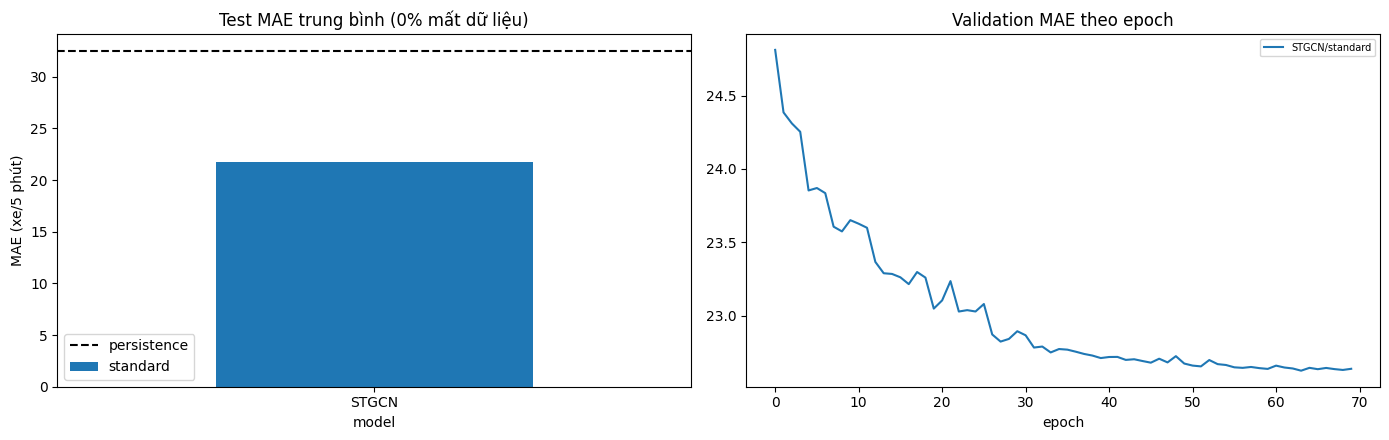

In [15]:
# --- Baseline tham chiếu: lặp lại giá trị cuối ---
base_model, _, base_te = train_model(train_data, val_data, test_data, "standard", "PERSIST", CFG["N_PAST"], verbose=False)
print("Persistence test MAE_avg:", round(base_te["MAE_avg"], 3))

# Chọn model theo validation, không dùng test để tránh rò rỉ.
best_row = exp1.sort_values("val_MAE").iloc[0]
BEST_MODEL, BEST_SCALER = best_row["model"], best_row["scaler"]
print(f"==> model tốt nhất theo validation: {BEST_MODEL} + {BEST_SCALER}")

# Hai biểu đồ: MAE test sạch theo model/scaler và đường validation theo epoch.
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
# Bảng model × scaler để so sánh trực quan.
piv = exp1.pivot(index="model", columns="scaler", values="test_MAE_avg")
piv.plot.bar(ax=ax[0], rot=0); ax[0].axhline(base_te["MAE_avg"], c="k", ls="--", label="persistence"); ax[0].legend()
ax[0].set_title("Test MAE trung bình (0% mất dữ liệu)"); ax[0].set_ylabel(f"MAE ({UNIT})")
for (m, s), h in HISTORY.items():
    if h["val_MAE"]: ax[1].plot(h["val_MAE"], label=f"{m}/{s}")
ax[1].set_title("Validation MAE theo epoch"); ax[1].set_xlabel("epoch"); ax[1].legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.show()


In [ ]:
sys.error("Dừng notebook tại đây để tránh chạy thí nghiệm mất dữ liệu quá lâu. "
         "Tiếp tục ở phần 2: robustness.ipynb")

### Kiểm tra nhanh: model học được phải **không tệ hơn persistence** ở mọi horizon
Nếu một graph model vẫn tệ hơn persistence (nhất là ở 15 phút), có lỗi cần xem lại trước khi tin các kết luận về không gian.

In [16]:
# --- Kiểm tra nhanh: model đã học không được tệ hơn persistence ở cả 3 horizon ---
cmp_cols = ["model", "scaler", "test_MAE_15", "test_MAE_30", "test_MAE_60", "test_MAE_avg"]
_r = results_df()
_p = _r[_r.model == "PERSIST"].iloc[0]
tbl = pd.concat([_r[_r.model == "PERSIST"][cmp_cols], exp1[cmp_cols].sort_values("test_MAE_avg")]).round(3).reset_index(drop=True)
display(tbl)
# So từng horizon với persistence; lệch > 1e-6 coi là tệ hơn.
for _, row in exp1.iterrows():
    bad = [h for h in (15, 30, 60) if row[f"test_MAE_{h}"] > _p[f"test_MAE_{h}"] + 1e-6]
    if bad: print(f"CẢNH BÁO: {row['model']}/{row['scaler']} tệ hơn persistence ở {bad} phút")


,model,scaler,test_MAE_15,test_MAE_30,test_MAE_60,test_MAE_avg
0,PERSIST,standard,24.932,30.290,42.353,32.525
1,STGCN,standard,19.291,21.198,24.768,21.752


## 11. Thí nghiệm 2 — huấn luyện chống hỏng cảm biến (masking augmentation)
Train lại đúng cấu hình tốt nhất nhưng thêm masking augmentation (`MASK_AUG` = tỉ lệ cảm biến hỏng tối đa trong batch). Đây là phần đóng góp chính: so sánh model **chuẩn** và model **robust** khi dữ liệu bị mất lúc test.

In [ ]:
# --- Thí nghiệm 2: train lại model tốt nhất với masking augmentation ---
# Model "chuẩn" đã có trong TRAINED; model "robust" học thêm với cảm biến bị giả lập hỏng.
std_model = TRAINED[(BEST_MODEL, BEST_SCALER)]
rob_model, rob_tr, rob_te = train_model(train_data, val_data, test_data, BEST_SCALER, BEST_MODEL, CFG["N_PAST"],
                                        mask_aug=CFG["MASK_AUG"], tag="+maskaug", verbose=False)
print(f"{BEST_MODEL}+maskaug | val MAE {rob_tr['best_val_MAE']:.3f} | val MAPE {rob_tr['best_val_MAPE']:.3f}% "
      f"| test MAE {rob_te['MAE_avg']:.3f} | test MAPE {rob_te['MAPE_avg']:.3f}%")

# Ba ứng viên đem so sánh trong các kịch bản mất dữ liệu.
CANDIDATES = {f"{BEST_MODEL} (chuẩn)": std_model, f"{BEST_MODEL} + maskaug": rob_model, "Persistence": base_model}


## 12. Thí nghiệm 3 — các kịch bản mất dữ liệu ngẫu nhiên
0% (sạch); 10% / 20% / 30% cảm biến mất trong 15 phút và 30 phút. Mỗi kịch bản lặp `N_REP` lần với cảm biến hỏng chọn ngẫu nhiên khác nhau, lấy trung bình.

In [ ]:
# --- Thí nghiệm 3: mất ngẫu nhiên 10/20/30% cảm biến trong 15/30 phút ---
# (0,0) = test sạch; sau đó 3 mức % mất × 2 thời lượng 15/30 phút.
SCEN = [(0, 0)] + [(p, mnt) for p in (10, 20, 30) for mnt in (15, 30)]
for label, mdl in CANDIDATES.items():
    for p, mnt in SCEN:
        # test_model tự ghi kết quả vào ROBUST với scenario="random".
        test_model(test_data, mdl.scaler, mdl, miss_pct=p, miss_minutes=mnt, label=label, scenario="random")

# Bảng MAE trung bình và MAE tại horizon 60 phút.
rb = robust_df().query("scenario == 'random'")
tab = rb.pivot_table(index=["miss_pct", "miss_minutes"], columns="model", values="MAE_avg").round(3)
display(tab)
display(rb.pivot_table(index=["miss_pct", "miss_minutes"], columns="model", values="MAPE_avg").round(3).rename_axis(columns="MAPE (%)"))
display(rb.pivot_table(index=["miss_pct", "miss_minutes"], columns="model", values="MAE_60").round(3).rename_axis(columns="MAE @60 phút"))

# Biểu đồ suy giảm MAE theo % cảm biến mất, tách 15 và 30 phút.
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for i, mnt in enumerate((15, 30)):
    for label in CANDIDATES:
        d = rb[(rb.model == label) & ((rb.miss_minutes == mnt) | (rb.miss_pct == 0))].sort_values("miss_pct")
        ax[i].plot(d.miss_pct, d.MAE_avg, marker="o", label=label)
    ax[i].set_title(f"Cảm biến mất {mnt} phút"); ax[i].set_xlabel("% cảm biến mất dữ liệu"); ax[i].grid(alpha=.3)
ax[0].set_ylabel(f"MAE trung bình ({UNIT})"); ax[0].legend()
plt.tight_layout(); plt.show()


## 13. Kịch bản khác 1 — cả một khu vực cảm biến bị mất
Chọn 1 cảm biến tâm, lấy `k` cảm biến **gần nhất** (liền kề về không gian, không ngẫu nhiên). Lặp qua 5 tâm khác nhau rồi lấy trung bình. So sánh với mất ngẫu nhiên cùng tỉ lệ để thấy mất theo cụm khó hơn.

In [ ]:
# --- Thí nghiệm 4: hỏng theo khu vực (tâm + k láng giềng gần nhất) ---
rng = np.random.default_rng(CFG["SEED"])
# 5 tâm cố định theo seed để kịch bản khu vực lặp lại được.
CENTERS = rng.choice(N_NODES, size=5, replace=False)

def run_region(label, mdl, pct, mnt):
    """Chạy lần lượt các tâm trong CENTERS, mỗi tâm lấy k cảm biến gần nhất.

    pct: % cảm biến mất; mnt: số phút mất. Kết quả là trung bình qua các tâm.
    """
    k = max(1, int(round(pct / 100 * N_NODES))); outs = []
    for c in CENTERS:
        outs.append(test_model(test_data, mdl.scaler, mdl, miss_pct=pct, miss_minutes=mnt, region=get_region(c, k),
                               n_rep=1, log=False))
    res = _avg(outs)
    ROBUST.append(dict(model=label, scenario="region", miss_pct=pct, miss_minutes=mnt, n_sensors_lost=k, **res))
    return res

for label, mdl in CANDIDATES.items():
    for pct in (10, 20, 30):
        for mnt in (15, 30):
            run_region(label, mdl, pct, mnt)

# So sánh trực tiếp khu vực vs ngẫu nhiên ở cùng tỉ lệ mất.
rg = robust_df().query("scenario == 'region'")
display(rg.pivot_table(index=["miss_pct", "miss_minutes"], columns="model", values="MAE_avg").round(3).rename_axis(columns="khu vực - MAE_avg"))
display(rg.pivot_table(index=["miss_pct", "miss_minutes"], columns="model", values="MAPE_avg").round(3).rename_axis(columns="khu vực - MAPE (%)"))
cmp = pd.concat([rb[rb.miss_pct > 0].assign(kind="ngẫu nhiên"), rg.assign(kind="khu vực")])
display(cmp[cmp.miss_minutes == 30].pivot_table(index="miss_pct", columns=["kind", "model"], values="MAE_avg").round(3))


## 14. Kịch bản khác 2 — loại bỏ thông tin không gian (ma trận kề)
Train lại **GNN** và **STGCN** với `use_adj=False` (ma trận kề → ma trận đơn vị: mỗi cảm biến chỉ nhìn chính nó) và so với bản có ma trận kề. Kỳ vọng: khi cảm biến hỏng, láng giềng giúp "vá" thông tin → bỏ không gian làm kết quả xấu đi, nhất là với mất theo khu vực (láng giềng cũng mất nên lợi ích giảm).

In [ ]:
# --- Thí nghiệm 5: ablation ma trận kề (có adj vs. thay bằng I) ---
# +adj: học quan hệ không gian; -adj: A = I, mỗi cảm biến dự báo độc lập.
abl = {}
for m in ("GNN", "STGCN"):
    # Tái dùng bản +adj từ exp1; train bổ sung nếu exp1 chưa chạy model/scaler này.
    key = (m, BEST_SCALER)
    if key not in TRAINED:
        print(f"Chưa có {key} trong TRAINED; đang train bản +adj...")
        mdl, _, _ = train_model(train_data, val_data, test_data, BEST_SCALER, m, CFG["N_PAST"],
                                use_adj=True, miss_rates=CFG["MISS_RATES"], tag="+adj", verbose=False)
        TRAINED[key] = mdl
    abl[f"{m} + adj"] = TRAINED[key]
    # Giữ cùng masking augmentation như exp1, chỉ thay đổi use_adj.
    mdl, _, _ = train_model(train_data, val_data, test_data, BEST_SCALER, m, CFG["N_PAST"],
                            use_adj=False, miss_rates=CFG["MISS_RATES"], tag="-noadj", verbose=False)
    abl[f"{m} - adj"] = mdl

# Đánh giá 4 kịch bản: sạch, ngẫu nhiên 20/30%, ngẫu nhiên 30/30%, khu vực 20/30%.
rows = []
for label, mdl in abl.items():
    for scen, (pct, mnt) in {"sạch 0%": (0, 0), "ngẫu nhiên 20%/30'": (20, 30), "ngẫu nhiên 30%/30'": (30, 30)}.items():
        r = test_model(test_data, mdl.scaler, mdl, miss_pct=pct, miss_minutes=mnt, label=label, scenario="ablation_adj")
        rows.append(dict(model=label, scenario=scen, MAE_avg=r["MAE_avg"], MAE_60=r["MAE_60"], MAPE_avg=r["MAPE_avg"]))
    r = run_region(label, mdl, 20, 30); rows.append(dict(model=label, scenario="khu vực 20%/30'", MAE_avg=r["MAE_avg"], MAE_60=r["MAE_60"], MAPE_avg=r["MAPE_avg"]))
abl_tab = pd.DataFrame(rows).pivot(index="model", columns="scenario", values="MAE_avg").round(3)
display(abl_tab)
display(pd.DataFrame(rows).pivot(index="model", columns="scenario", values="MAPE_avg").round(3).rename_axis(columns="MAPE (%)"))
abl_tab.T.plot.bar(figsize=(11, 4.5), rot=15); plt.ylabel(f"MAE trung bình ({UNIT})"); plt.title("Ablation: có / không ma trận kề"); plt.tight_layout(); plt.show()


## 15. Tổng hợp & lưu kết quả

In [0]:
# --- Lưu toàn bộ bảng kết quả ra CSV để đưa vào báo cáo ---
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
results_df().drop(columns=[], errors="ignore").to_csv(OUTPUT_DIR / "results_train_test.csv", index=False)
robust_df().to_csv(OUTPUT_DIR / "results_robustness.csv", index=False)
print(f"Đã lưu {OUTPUT_DIR / 'results_train_test.csv'} và {OUTPUT_DIR / 'results_robustness.csv'}")
display(results_df().round(3).tail(10))
display(robust_df().round(3).tail(10))


Đã lưu /run/media/hoang/HDD-512GB/outputs/results_train_test.csv và /run/media/hoang/HDD-512GB/outputs/results_robustness.csv


,model,scaler,n_past,mask_aug,use_adj,seed,tag,n_params,best_epoch,train_time_s,...,test_MAPE_15,test_MAE_30,test_RMSE_30,test_MAPE_30,test_MAE_60,test_RMSE_60,test_MAPE_60,test_MAE_avg,test_RMSE_avg,test_MAPE_avg
3,GNN,standard,12,0.0,True,42,,20995,34,75.7,...,2.925,1.799,4.054,4.145,2.272,5.160,5.635,1.818,4.049,4.235
4,GNN,minmax,12,0.0,True,42,,20995,38,76.9,...,2.907,1.829,4.112,4.114,2.340,5.280,5.722,1.856,4.119,4.248
5,GNN,log,12,0.0,True,42,,20995,20,50.4,...,2.916,1.812,4.053,4.088,2.298,5.167,5.584,1.835,4.052,4.196
6,STGCN,standard,12,0.0,True,42,,95747,30,882.2,...,2.914,1.781,3.994,4.158,2.228,5.041,5.559,1.793,3.973,4.210
7,STGCN,minmax,12,0.0,True,42,,95747,40,951.3,...,2.885,1.788,3.969,4.032,2.243,4.998,5.422,1.804,3.953,4.113
8,STGCN,log,12,0.0,True,42,,95747,40,955.2,...,2.881,1.783,3.969,4.053,2.231,4.997,5.388,1.796,3.947,4.107
9,PERSIST,standard,12,0.0,True,42,,0,0,0.8,...,3.231,2.171,4.946,4.641,3.039,6.982,6.823,2.267,5.105,4.898
10,STGCN,standard,12,0.3,True,42,+maskaug,95747,40,958.5,...,2.895,1.776,3.973,4.085,2.219,5.007,5.457,1.788,3.955,4.146
11,GNN,standard,12,0.0,False,42,-noadj,20995,20,49.2,...,2.953,1.833,4.139,4.205,2.321,5.266,5.790,1.852,4.137,4.316
12,STGCN,standard,12,0.0,False,42,-noadj,95747,30,854.5,...,2.953,1.820,4.125,4.240,2.301,5.240,5.787,1.837,4.114,4.327


,model,scenario,miss_pct,miss_minutes,n_sensors_lost,MAE_15,RMSE_15,MAPE_15,MAE_30,RMSE_30,MAPE_30,MAE_60,RMSE_60,MAPE_60,MAE_avg,RMSE_avg,MAPE_avg
45,GNN - adj,ablation_adj,30,30,98,1.699,3.880,3.746,2.117,4.757,5.053,2.692,5.892,6.747,2.170,4.843,5.182
46,GNN - adj,region,20,30,65,1.597,3.600,3.476,2.018,4.544,4.759,2.566,5.671,6.417,2.061,4.605,4.884
47,STGCN + adj,ablation_adj,0,0,0,1.371,2.885,2.914,1.781,3.994,4.158,2.228,5.041,5.559,1.793,3.973,4.210
48,STGCN + adj,ablation_adj,20,30,65,1.580,3.418,3.440,1.992,4.406,4.712,2.515,5.477,6.221,2.029,4.433,4.791
49,STGCN + adj,ablation_adj,30,30,98,1.687,3.668,3.709,2.100,4.603,4.997,2.664,5.698,6.569,2.150,4.656,5.092
50,STGCN + adj,region,20,30,65,1.583,3.475,3.446,1.978,4.401,4.695,2.491,5.484,6.198,2.017,4.453,4.780
51,STGCN - adj,ablation_adj,0,0,0,1.392,2.978,2.953,1.820,4.125,4.240,2.301,5.240,5.787,1.837,4.114,4.327
52,STGCN - adj,ablation_adj,20,30,65,1.598,3.568,3.479,1.998,4.491,4.735,2.502,5.576,6.293,2.033,4.545,4.835
53,STGCN - adj,ablation_adj,30,30,98,1.703,3.833,3.746,2.089,4.667,4.986,2.605,5.741,6.551,2.132,4.747,5.095
54,STGCN - adj,region,20,30,65,1.597,3.563,3.480,1.996,4.486,4.736,2.500,5.573,6.297,2.031,4.541,4.838


## 16. Tổng kết

**Bài toán.** Dự báo lưu lượng xe (flow, xe/5 phút) PeMS04 cho 307 cảm biến tại các mốc **15 / 30 / 60 phút** từ 12 bước quá khứ (60 phút), đồng thời đánh giá độ bền khi một phần cảm biến mất dữ liệu lúc suy luận.

**Pipeline.** Làm sạch dữ liệu → chia liền mạch theo thời gian 70/10/20 → imputer nhân quả (forward-fill + median train) → scaler fit trên train → cửa sổ trượt → huấn luyện GRU / GNN / STGCN → chọn model theo **validation** → test sạch và các kịch bản cảm biến hỏng.

**Input / output.** Mỗi mẫu vào `(12, 307, 5)`: giá trị đã scale, mask quan sát, sin/cos giờ trong ngày và cờ cuối tuần. Đầu ra `(307, 3)` cho ba horizon. Các model dùng **residual**: dự báo = giá trị cuối + phần chênh học được, nên khởi điểm không tệ hơn persistence.

**Điểm chính.**
- **Mask** giúp model phân biệt giá trị thật với giá trị bù.
- **Masking augmentation** giúp model quen với cảm biến hỏng trong lúc train.
- **Đánh giá có kiểm soát**: mất ngẫu nhiên 10/20/30% trong 15/30 phút, mất theo khu vực, và ablation bỏ ma trận kề.
- **Persistence** là baseline bắt buộc; nên báo cáo cả MAE tuyệt đối và mức tăng khi có sự cố.

**Hạn chế.** Một seed, một cách chia thời gian, dữ liệu PeMS04 chỉ 2 tháng (01–02/2018) nên test ~12 ngày; đồ thị PeMS04 thưa (~340 cạnh); chưa tối ưu hyperparameter; lợi ích của graph model chưa chắc ổn định qua mọi kịch bản.
